# 01 — Exploratory Data Analysis: WiDS 2024 Challenge #1

**Course:** Data Mining and Applications, HCMUS. **Stage:** read-only exploratory analysis.

This notebook investigates data structure, semantic roles, missingness, distributions, and
associations to formulate preprocessing hypotheses, without validating a chosen method. Outputs are computed from the local official
training CSV. They are descriptive observations about this training sample, not validated
clinical claims, causal effects, or estimates of predictive performance.

## 1. Problem definition, source, and limitations

- **Official source:** [WiDS Datathon 2024 — Challenge #1, Data](https://www.kaggle.com/competitions/widsdatathon2024-challenge1/data)
  and [competition rules](https://www.kaggle.com/competitions/widsdatathon2024-challenge1/rules).
- **Outcome:** supplied binary column `DiagPeriodL90D`; **identifier:** `patient_id`.
  The official Data dictionary describes the event as a diagnosis period shorter than 90 days
  and attributes the cohort to HealthVerity metastatic triple-negative breast-cancer records.
  The interval's precise date anchors, the boundary wording (<90 versus ‘within 90’), explicit
  numeric 0/1 mapping and record-level eligibility remain unverified; retain labels **0 and 1**.
  The field-level source/timing audit below separates documented facts from unresolved details.
- **Input contract:** `data/raw/training.csv`, expected 12,906 rows and 83 columns.
  `sample_submission.csv` is a submission template and is never read. No test CSV is read.
- **Provisional prediction question:** could information available at a baseline breast-cancer
  diagnosis predict this supplied outcome? This is a **working temporal scenario**, not a
  verified competition protocol. The actual prediction time must be confirmed before modeling.
- **Scope and limitations:** this is a selected observational training sample. Patient uniqueness
  does not establish independent sampling; patients share geographic context. Feature dates,
  collection processes, units, and data provenance within the cohort are not supplied in this CSV.
  Associations may reflect selection, recording, geographic clustering, and confounding.
  Exploring labels on the full training sample is hypothesis generation; later model evaluation
  needs a declared validation design. Every row and its label has already contributed to EDA;
  a later split of this same file cannot be described as a completely untouched test set.

**Read-only contract:** no rows or columns are removed from the loaded training frame; no
imputation, scaling, encoding, outlier treatment, feature selection, or model fitting is performed.
Selections and group summaries below are temporary diagnostics. Only this notebook's outputs are
saved. The final cell checks both the CSV checksum and the in-memory frame fingerprint.

**Official-rubric audit (25 October 2026):** the complete official assignment page was retrieved
with HTTP 200 and audited before these corrections. Required EDA includes all-feature normality
tests, full Pearson/Spearman correlation coverage, `missingno.matrix`, and Little's MCAR test.
See the repository's `RUBRIC_AUDIT.md` for the before/final matrices, future requirements, grading
ambiguities, and criteria that remain PARTIAL or NOT VERIFIED. A numerical calculation is not
by itself proof of statistical assumptions or full rubric compliance.

**Reading guide:** normality, full correlations and missingno/Little are required tabular EDA.
Schema, distributions and category support explain the data. Wider-scope, ZIP-weighting and
seven reference tests are supporting/supplementary diagnostics; expandable tables retain detail.


In [1]:
from pathlib import Path
import hashlib
import platform
import sys
from importlib.metadata import version
from textwrap import fill

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import missingno as msno
import warnings
from statsmodels.stats.multitest import multipletests
from IPython.display import display, Markdown, HTML

# Works from the repository root, book/, or book/tabular/; no machine-specific paths.
ROOT = next(
    (p for p in (Path.cwd(), *Path.cwd().parents)
     if (p / "myst.yml").is_file() and (p / "src/validate_dataset.py").is_file()),
    None,
)
if ROOT is None:
    raise RuntimeError("Start Jupyter inside the data-mining-preprocessing repository.")
if Path(sys.prefix) != ROOT / ".venv":
    raise RuntimeError("Select the project's .venv kernel (hcmus-wids), then restart and run all.")

if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
DATA_PATH = ROOT / "data/raw/training.csv"
TARGET, ID = "DiagPeriodL90D", "patient_id"
EXPECTED_SHAPE = (12906, 83)  # Input contract; edit or set None when adapting to another dataset.
RANDOM_STATE = 42
NEAR_CONSTANT_SHARE = 0.95
RARE_SHARE = 0.01
MIN_CORRELATION_N = 100
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 140})
pd.set_option("display.max_columns", 14)
print(f"Python {platform.python_version()}; verified kernel: .venv/bin/python")
display(pd.DataFrame({
    "package": ["numpy", "pandas", "matplotlib", "seaborn", "scipy", "statsmodels"],
    "version": [version(p) for p in ["numpy", "pandas", "matplotlib", "seaborn", "scipy", "statsmodels"]],
}))

# Reuse: update DATA_PATH, TARGET, ID, EXPECTED_SHAPE, then review semantic/plot/test lists below.
# Numerical storage alone never establishes that a new feature is a continuous measurement.
ALPHA = 0.05
STRONG_CORRELATION = 0.9


Python 3.13.3; verified kernel: .venv/bin/python


,package,version
0,numpy,2.5.4
1,pandas,3.1.0
2,matplotlib,3.11.2
3,seaborn,0.13.2
4,scipy,1.18.1
5,statsmodels,0.15.0


## 2. Loading, schema, integrity, and class balance

**Question:** is this the expected labeled training file, and are IDs and labels usable for
exploration? Read exactly the training path and verify the supplied shape and column contract.
Pandas' default NA recognition is recorded explicitly; a later lexical read checks candidate
sentinel tokens without replacing them. No patient rows or IDs are displayed in publication.

**ZIP parsing audit:** compare the literal `patient_zip3` tokens in this CSV with pandas' default
inference. Then load that identifier explicitly as `string`, preserving any leading zeros in
future files without inventing zero-padding. The CSV itself cannot establish whether a code
was altered upstream. The literal `999` is retained; its geographic validity or possible
sentinel meaning needs a dictionary, not a numeric rule.

Input preparation: existing training.csv; no download or replacement performed


,ZIP parsing audit
default pandas ZIP dtype,int64
chosen ZIP storage dtype,string
ZIP semantic role,geographic code / nominal category
literal ZIP rows,12906
distinct literal ZIP codes,739
leading-zero rows in this CSV,0
tokens not exactly three digits,0
"literal 999 rows, retained",1


,observed
rows,12906
columns,83
feature_columns,81
missing_IDs,0
duplicate_nonmissing_IDs_after_first,0
duplicate_rows_after_first,0
missing_labels,0
deep_memory_MiB,14.967


Input SHA-256: e9947ecfe1cdacafbf9cbcdc0abd024396f617c701b056fa54e5881f1bb9bbe9


,patients,share_pct
class,,
0,4846,37.548
1,8060,62.452


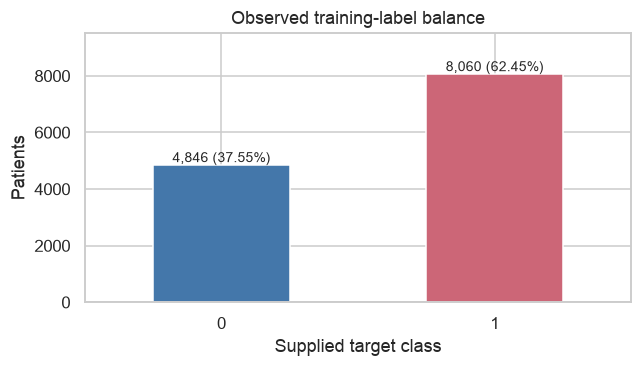

**Observed:** class 1 accounts for **62.45%** and class 0 for **37.55%**. This is unequal class representation, not evidence that resampling is needed. Later evaluation should compare suitable metrics against a majority-class reference; no classifier or resampling is run here. Unique IDs do not rule out repeat patients under different IDs.

In [2]:
# Optional cold-start preparation: never replace an existing training CSV.
# Credentials/rules acceptance must be configured by the user outside this notebook.
DOWNLOAD_IF_MISSING = False
download_performed = False
if not DATA_PATH.is_file() and DOWNLOAD_IF_MISSING:
    import subprocess
    import zipfile
    import shutil
    DATA_PATH.parent.mkdir(parents=True, exist_ok=True)
    subprocess.run([str(ROOT / ".venv/bin/kaggle"), "competitions", "download",
                    "widsdatathon2024-challenge1", "-p", str(DATA_PATH.parent)], check=True)
    archive_path = DATA_PATH.parent / "widsdatathon2024-challenge1.zip"
    with zipfile.ZipFile(archive_path) as archive:
        candidates = [name for name in archive.namelist() if Path(name).name.casefold() == "training.csv"]
        if len(candidates) != 1:
            raise ValueError("Official archive does not contain exactly one training.csv")
        with archive.open(candidates[0]) as source, DATA_PATH.open("xb") as destination:
            shutil.copyfileobj(source, destination)
    download_performed = True
if not DATA_PATH.is_file():
    raise FileNotFoundError("Download the official training.csv after Kaggle authentication/rules acceptance; see README.")
print("Input preparation:", "downloaded the official training file" if download_performed
      else "existing training.csv; no download or replacement performed")
raw_sha256_before = hashlib.sha256(DATA_PATH.read_bytes()).hexdigest()
zip_tokens = pd.read_csv(
    DATA_PATH, usecols=["patient_zip3"], dtype="string", keep_default_na=False
)["patient_zip3"]
default_zip_dtype = str(pd.read_csv(DATA_PATH, usecols=["patient_zip3"]).patient_zip3.dtype)
zip_leading_zero_n = int(zip_tokens.str.startswith("0").sum())
zip_literal_999_n = int(zip_tokens.eq("999").sum())

# Set storage type at read time; do not repair, pad, encode, or overwrite geographic codes.
df = pd.read_csv(DATA_PATH, dtype={"patient_zip3": "string"})
if EXPECTED_SHAPE is not None:
    assert df.shape == EXPECTED_SHAPE, f"Unexpected training shape: {df.shape}"
shape_before = df.shape
# Fail visibly if the selected parsing loses or changes any literal ZIP token.
assert df.patient_zip3.equals(zip_tokens), "ZIP parsing did not preserve all literal CSV tokens"
display(pd.Series({
    "default pandas ZIP dtype": default_zip_dtype,
    "chosen ZIP storage dtype": str(df.patient_zip3.dtype),
    "ZIP semantic role": "geographic code / nominal category",
    "literal ZIP rows": len(zip_tokens),
    "distinct literal ZIP codes": zip_tokens.nunique(),
    "leading-zero rows in this CSV": zip_leading_zero_n,
    "tokens not exactly three digits": int((~zip_tokens.str.fullmatch(r"[0-9]{3}")).sum()),
    "literal 999 rows, retained": zip_literal_999_n,
}, name="ZIP parsing audit").to_frame())
assert {ID, TARGET}.issubset(df.columns)
assert df.columns.is_unique
assert df[TARGET].notna().all() and set(df[TARGET].unique()) == {0, 1}
frame_fingerprint_before = hashlib.sha256(
    pd.util.hash_pandas_object(df, index=True).to_numpy().tobytes()
).hexdigest()
dtypes_before = df.dtypes.copy()

feature_columns = [c for c in df.columns if c not in {ID, TARGET}]
integrity = pd.Series({
    "rows": len(df), "columns": len(df.columns), "feature_columns": len(feature_columns),
    "missing_IDs": int(df[ID].isna().sum()),
    "duplicate_nonmissing_IDs_after_first": int(df.loc[df[ID].notna(), ID].duplicated().sum()),
    "duplicate_rows_after_first": int(df.duplicated().sum()),
    "missing_labels": int(df[TARGET].isna().sum()),
    "deep_memory_MiB": round(df.memory_usage(index=True, deep=True).sum() / 1024**2, 3),
}, name="observed", dtype="object")
display(integrity.to_frame().round(3))
print("Input SHA-256:", raw_sha256_before)

balance = df[TARGET].value_counts().reindex([0, 1]).rename("patients").to_frame()
balance["share_pct"] = balance["patients"] / len(df) * 100
balance.index.name = "class"
display(balance.round(3))
ax = balance["patients"].plot.bar(color=["#4477AA", "#CC6677"], rot=0, figsize=(6, 3.5))
ax.set(title="Observed training-label balance", xlabel="Supplied target class", ylabel="Patients")
for bar, pct in zip(ax.patches, balance["share_pct"]):
    ax.annotate(f"{int(bar.get_height()):,} ({pct:.2f}%)",
                (bar.get_x() + bar.get_width()/2, bar.get_height()),
                ha="center", va="bottom", fontsize=9)
ax.set_ylim(0, balance.patients.max() * 1.18)
plt.tight_layout()
plt.show()
display(Markdown(
    f"**Observed:** class 1 accounts for **{balance.loc[1, 'share_pct']:.2f}%** "
    f"and class 0 for **{balance.loc[0, 'share_pct']:.2f}%**. "
    "This is unequal class representation, not evidence that resampling is needed. "
    "Later evaluation should compare suitable metrics against a majority-class reference; "
    "no classifier or resampling is run here. Unique IDs do not rule out repeat patients under different IDs."
))

## 3. Semantic feature audit and temporal leakage review

**Question:** what does each feature measure, and could it exist at the proposed prediction time?
Storage dtype, documented meaning, temporal availability and predictive eligibility are different.

**Source review, 25 October 2026:** the [official Kaggle Data dictionary](https://www.kaggle.com/competitions/widsdatathon2024-challenge1/data)
was readable through its search-indexed text; the direct page returned a JavaScript shell, not
the dictionary. The [WiDS technical director's tutorial](https://www.widsworldwide.org/get-inspired/blog/triple-negative-breast-cancer-datathon-a-tutorial/)
corroborates the challenge context. These source checks are recorded here, not fetched at runtime.
They do not certify the CSV's individual code values or patient-level chronology.

| Field/group | Source-confirmed information | Still unverified / implication for baseline prediction |
|---|---|---|
| `DiagPeriodL90D` | Indicator for diagnosis period shorter than 90 days | Exact date anchors, 90-day boundary and explicit 0/1 coding; no reconstructed duration |
| `patient_age` | Index year minus birth year | Index-year definition and availability at the proposed baseline |
| `bmi` | First available BMI after metastatic diagnosis | Post-diagnosis ascertainment; cannot be approved for an earlier prediction time |
| Diagnosis code/description fields | Breast codes use ICD-9/ICD-10; metastatic codes use ICD-10 | Exact code editions, individual meanings and recording dates; no code lookup invented |
| Two novel-treatment fields | First novel drug and treatment type after metastatic diagnosis | Post-event information; not baseline predictors in the proposed scenario |
| `payer_type`, state, ZIP3, gender | Recorded on the metastatic date | Whether the same information was available at an earlier baseline |
| Socioeconomic/contextual columns | Area summaries; household median income in USD, density per km² | Exact release, ZIP-to-ZIP3 aggregation, anonymization effects and historical availability |
| `Ozone`, `PM25`, `N02` | Annual ZIP3 concentrations of O3, PM2.5 and NO2 | Units, reference years and exposure windows; preserve the literal CSV spelling `N02` |

**Source quality matters:** the dictionary's `poverty` entry duplicates a home-value definition.
Its meaning therefore remains **UNVERIFIED**; do not silently replace it with a poverty-rate
interpretation inferred from the name. Region/Division and Ozone capitalization differ between
the dictionary and CSV; original column names are retained. Individual disease-code meanings,
BMI units and geographic validity of `999` have not been verified.

**Temporal gate:** a prediction before metastatic diagnosis is the working scenario, not a
verified competition deployment protocol. BMI and treatment are documented post-metastatic;
at-event attributes also need historical availability checks. Inclusion in the competition
table does not establish prospective availability. The later project must distinguish a
supplied-table competition benchmark from a prospective clinical prediction question.

- `patient_zip3` is a nominal geographic code stored as `string`; numerical storage would not
  justify continuous distances/correlations. No padding or geographic enrichment is performed.
- Five diagnosis/treatment code/text fields remain outside target-association tests. The existing
  BMI/target and BMI-missingness comparisons are retained as **retrospective recording diagnostics**,
  not evidence for selecting a baseline predictor. BMI and its missingness indicator inherit the
  same post-diagnosis availability concern. No new label-based tests are introduced.
- All 69 numerical candidates, including BMI, remain in required descriptive normality/correlation
  audits. Describing a variable does not approve it for modeling. No feature is removed from `df`.
- An observed constant may still have varying missingness. The 95% near-constant threshold is a
  diagnostic convention, not a deletion rule or a course requirement.


In [3]:
clinical_review = {
    "breast_cancer_diagnosis_code", "breast_cancer_diagnosis_desc",
    "metastatic_cancer_diagnosis_code", "metastatic_first_novel_treatment",
    "metastatic_first_novel_treatment_type",
}
geographic_codes = {"patient_zip3", "patient_state", "Region", "Division"}
individual_categorical = {"patient_race", "payer_type", "patient_gender"}
individual_numeric = {"patient_age", "bmi"}
environment_columns = {"Ozone", "PM25", "N02"}  # Preserve the literal CSV name N02 (zero).

def timing_status(column):
    if column in {"bmi", "metastatic_first_novel_treatment", "metastatic_first_novel_treatment_type"}:
        return "post-metastatic: documented; earlier-baseline use blocked"
    if column in {"payer_type", "patient_state", "patient_zip3", "patient_gender"}:
        return "on metastatic date: documented; baseline availability unverified"
    if column == "patient_age":
        return "index-year age: documented; index/baseline alignment unverified"
    if column in clinical_review:
        return "code system documented; individual definition/timing unverified"
    return "baseline availability/reference period unverified"


def semantic_role(column):
    if column in clinical_review:
        return "clinical code/text; temporal review"
    if column in geographic_codes:
        return "geographic category/code"
    if column in individual_categorical:
        return "individual nominal category"
    if column in individual_numeric:
        return "candidate individual numerical"
    if column in environment_columns:
        return "candidate contextual/environmental"
    if pd.api.types.is_numeric_dtype(df[column]):
        return "candidate contextual numerical"
    return "unclassified; review required"

records = []
for column in feature_columns:
    observed_counts = df[column].value_counts()
    records.append({
        "feature": column, "storage_dtype": str(df[column].dtype),
        "semantic_role": semantic_role(column),
        "missing_pct": df[column].isna().mean() * 100,
        "observed_unique": df[column].nunique(),
        "dominant_observed_pct": (observed_counts.iloc[0] / observed_counts.sum() * 100
                                  if len(observed_counts) else np.nan),
        "timing_status": timing_status(column),
    })
audit = pd.DataFrame(records).set_index("feature")
continuous_columns = [
    c for c in feature_columns
    if c not in clinical_review | geographic_codes | individual_categorical
    and pd.api.types.is_numeric_dtype(df[c])
]
categorical_columns = [c for c in feature_columns if c not in continuous_columns]
assert len(audit) == len(feature_columns)
assert ID not in continuous_columns and TARGET not in continuous_columns
assert set(continuous_columns) | set(categorical_columns) == set(feature_columns)
assert "patient_zip3" in categorical_columns and "patient_zip3" not in continuous_columns
with pd.option_context("display.max_rows", 90):
    display(audit.round(3))
print(f"Semantic feature counts: {len(continuous_columns)} numerical candidates, "
      f"{len(categorical_columns)} categorical/code/text candidates; target and ID excluded.")
print("patient_zip3 categories:", df.patient_zip3.nunique())

single_observed = audit.loc[audit.observed_unique <= 1]
near_constant = audit.loc[
    (audit.observed_unique > 1) & (audit.dominant_observed_pct >= 100 * NEAR_CONSTANT_SHARE)
]
display(Markdown("**Single observed category / all-missing audit:**"))
display(single_observed[["observed_unique", "missing_pct", "dominant_observed_pct"]].round(3))
display(Markdown("**Near-constant features (excluding single-category columns):**"))
display(near_constant[["observed_unique", "dominant_observed_pct", "missing_pct"]].round(3))

code_to_description = df.groupby("breast_cancer_diagnosis_code")["breast_cancer_diagnosis_desc"].nunique()
description_to_code = df.groupby("breast_cancer_diagnosis_desc")["breast_cancer_diagnosis_code"].nunique()
print("Maximum descriptions per breast diagnosis code:", code_to_description.max())
print("Maximum breast diagnosis codes per description:", description_to_code.max())
print("An observed one-to-one mapping is a redundancy clue, not verification of code meanings.")

# Published tabular-selection requirements, checked on actual semantic features.
dataset_rubric = pd.Series({
    "rows_at_least_10000": len(df) >= 10000,
    "attributes_at_least_10_excluding_ID_target": len(feature_columns) >= 10,
    "has_numerical_and_categorical": bool(continuous_columns and categorical_columns),
    "at_least_one_feature_missing_5pct": bool((audit.missing_pct >= 5).any()),
}, name="rubric_met")
display(dataset_rubric.to_frame())
assert dataset_rubric.all()


,storage_dtype,semantic_role,missing_pct,observed_unique,dominant_observed_pct,timing_status
feature,,,,,,
patient_race,str,individual nominal category,49.473,5,55.022,baseline availability/reference period unverified
payer_type,str,individual nominal category,13.970,3,54.328,on metastatic date: documented; baseline avail...
patient_state,str,geographic category/code,0.395,50,18.965,on metastatic date: documented; baseline avail...
patient_zip3,string,geographic category/code,0.000,739,1.852,on metastatic date: documented; baseline avail...
patient_age,int64,candidate individual numerical,0.000,67,3.649,index-year age: documented; index/baseline ali...
patient_gender,str,individual nominal category,0.000,1,100.000,on metastatic date: documented; baseline avail...
bmi,float64,candidate individual numerical,69.464,1342,2.893,post-metastatic: documented; earlier-baseline ...
breast_cancer_diagnosis_code,str,clinical code/text; temporal review,0.000,50,15.357,code system documented; individual definition/...
breast_cancer_diagnosis_desc,str,clinical code/text; temporal review,0.000,50,15.357,code system documented; individual definition/...


Semantic feature counts: 69 numerical candidates, 12 categorical/code/text candidates; target and ID excluded.
patient_zip3 categories: 739


**Single observed category / all-missing audit:**

,observed_unique,missing_pct,dominant_observed_pct
feature,,,
patient_gender,1,0.000,100.0
metastatic_first_novel_treatment_type,1,99.814,100.0


**Near-constant features (excluding single-category columns):**

,observed_unique,dominant_observed_pct,missing_pct
feature,,,


Maximum descriptions per breast diagnosis code: 1
Maximum breast diagnosis codes per description: 1
An observed one-to-one mapping is a redundancy clue, not verification of code meanings.


,rubric_met
rows_at_least_10000,True
attributes_at_least_10_excluding_ID_target,True
has_numerical_and_categorical,True
at_least_one_feature_missing_5pct,True


## 4. Missing-value analysis

**Questions:** how much is missing, which masks co-occur, and what can be inferred about recording?
Percentages use all training rows unless an observed-case/class denominator is stated.
Temporary boolean indicators do not modify the training frame.

Keep both missingno views: focus = at most 250 rows, seed 42, eight columns; overview = all rows,
all 81 features. White denotes missing values. The phi heatmap is supporting evidence: a rounded
correlation of 1 does not prove identical masks, so counts check selected masks explicitly.
Long plot labels are shortened only for display; full feature names remain in the audit/key.

The **Missingness Mechanism Assessment** separates observed evidence from plausible hypotheses
and unknowns. Class 1 − class 0 missing-rate differences are percentage points, not mechanism labels.
No missingness mechanism is confirmed by these tables, plots or reference p-values.


,missing_n,missing_pct,observed_n
metastatic_first_novel_treatment,12882,99.814,24
metastatic_first_novel_treatment_type,12882,99.814,24
bmi,8965,69.464,3941
patient_race,6385,49.473,6521
payer_type,1803,13.970,11103
Region,52,0.403,12854
Division,52,0.403,12854
patient_state,51,0.395,12855
Ozone,29,0.225,12877
PM25,29,0.225,12877


,missing_feature_count_per_row
count,12906.000000
mean,3.354409
std,1.030151
min,0.000000
50%,3.000000
90%,4.000000
99%,5.000000
max,67.000000


Rows with any missing feature: 12,903 / 12,906 (99.98%)


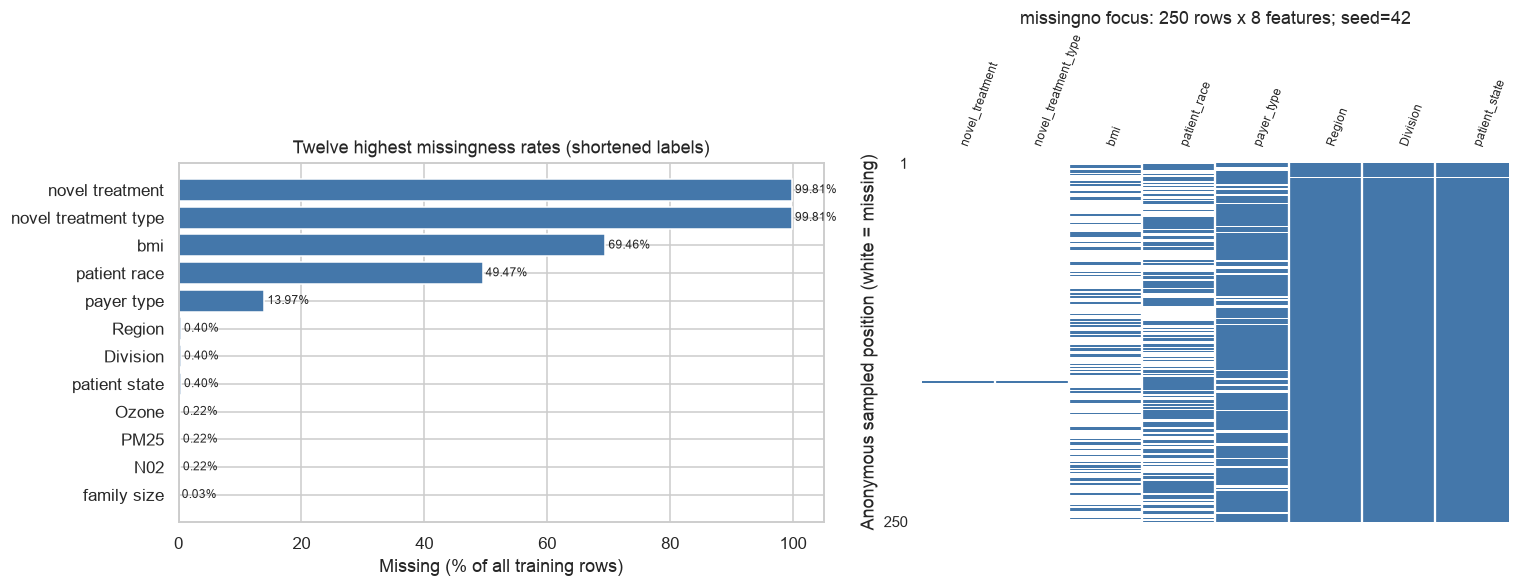

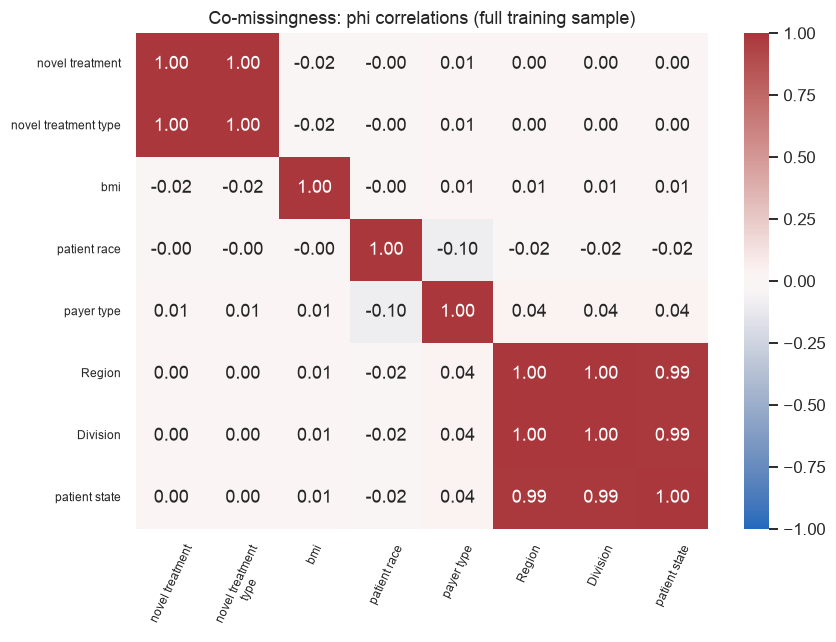

In [4]:
missing_counts = df[feature_columns].isna().sum().sort_values(ascending=False, kind="stable")
missing_table = missing_counts.rename("missing_n").to_frame()
missing_table["missing_pct"] = missing_table.missing_n / len(df) * 100
missing_table["observed_n"] = len(df) - missing_table.missing_n
with pd.option_context("display.max_rows", 90):
    display(missing_table.round(3))
row_missing = df[feature_columns].isna().sum(axis=1)
assert int(missing_counts.sum()) == int(row_missing.sum())
assert (missing_table.missing_n + missing_table.observed_n == len(df)).all()
display(row_missing.describe(percentiles=[0.5, 0.9, 0.99]).rename("missing_feature_count_per_row").to_frame())
print(f"Rows with any missing feature: {int((row_missing > 0).sum()):,} / {len(df):,} "
      f"({(row_missing > 0).mean():.2%})")

missing_columns = missing_counts[missing_counts > 0].index.tolist()
indicators = df[missing_columns].isna()
missing_focus = missing_columns[:8]
sampled_indicators = indicators[missing_focus].sample(n=min(250, len(df)), random_state=RANDOM_STATE)

plot_alias = {"metastatic_first_novel_treatment": "novel_treatment",
              "metastatic_first_novel_treatment_type": "novel_treatment_type"}

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5), gridspec_kw={"width_ratios": [1.1, 1]})
top_missing = missing_table.head(12).iloc[::-1]
axes[0].barh([fill(plot_alias.get(c, c).replace("_", " "), 30) for c in top_missing.index], top_missing.missing_pct, color="#4477AA")
axes[0].set(xlabel="Missing (% of all training rows)", xlim=(0, 105), title="Twelve highest missingness rates (shortened labels)")
for i, pct in enumerate(top_missing.missing_pct):
    axes[0].text(pct + 0.5, i, f"{pct:.2f}%", va="center", fontsize=8)
focus_matrix = df[missing_focus].sample(n=min(250, len(df)), random_state=RANDOM_STATE)
# Plot-only aliases/positions; the original frame is not renamed or reordered.
focus_matrix = focus_matrix.rename(columns=plot_alias).set_axis(range(len(focus_matrix)), axis="index")
msno.matrix(focus_matrix, ax=axes[1], sparkline=False, labels=True, fontsize=8,
            label_rotation=70, color=(0.27, 0.47, 0.67))
axes[1].set(title=f"missingno focus: {len(focus_matrix)} rows x {len(missing_focus)} features; seed={RANDOM_STATE}",
            ylabel="Anonymous sampled position (white = missing)")
plt.tight_layout()
plt.show()

# Phi = Pearson correlation between binary missingness indicators; never between raw codes.
phi = indicators[missing_focus].astype(int).corr()
fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(phi, annot=True, fmt=".2f", vmin=-1, vmax=1, center=0, cmap="vlag",
            xticklabels=[fill(plot_alias.get(c, c).replace("_", " "), 18) for c in missing_focus],
            yticklabels=[fill(plot_alias.get(c, c).replace("_", " "), 22) for c in missing_focus], ax=ax)
ax.set_title("Co-missingness: phi correlations (full training sample)")
ax.tick_params(axis="x", rotation=65, labelsize=8)
ax.tick_params(axis="y", rotation=0, labelsize=8)
plt.tight_layout()
plt.show()

In [5]:
pattern_keys = {column: f"M{i+1}" for i, column in enumerate(missing_focus)}
patterns = indicators[missing_focus].astype(int).astype(str).agg("".join, axis=1).value_counts()
assert int(patterns.sum()) == len(df)
assert (patterns.index.str.len() == len(missing_focus)).all()
pattern_table = patterns.head(10).rename("patients").to_frame()
pattern_table["share_pct"] = pattern_table.patients / len(df) * 100
print("Pattern order:", pattern_keys)
print("1 = missing; 0 = observed. Patterns cover only the eight selected columns.")
print(f"Coverage of displayed patterns: {pattern_table.patients.sum()/len(df):.2%}")

missing_class_counts = indicators.groupby(df[TARGET]).sum().T.reindex(columns=[0, 1])
assert missing_class_counts.sum(axis=1).equals(missing_counts.loc[missing_columns])
missing_by_class = missing_class_counts.div(balance["patients"], axis="columns") * 100
missing_by_class.columns = ["missing_pct_class0", "missing_pct_class1"]
missing_by_class["difference_pp_class1_minus_class0"] = (
    missing_by_class.missing_pct_class1 - missing_by_class.missing_pct_class0
)
for label in [0, 1]:
    missing_by_class[f"observed_n_class{label}"] = (
        balance.loc[label, "patients"] - missing_class_counts[label]
    )
    reconstructed_n = missing_by_class[f"missing_pct_class{label}"] * balance.loc[label, "patients"] / 100
    assert np.allclose(reconstructed_n, missing_class_counts[label])
print("Class denominators:", balance["patients"].to_dict())

co_missing_records = []
for left, right in [("Region", "Division"),
                    ("metastatic_first_novel_treatment", "metastatic_first_novel_treatment_type")]:
    left_missing, right_missing = df[left].isna(), df[right].isna()
    co_missing_records.append({
        "pair": f"{plot_alias.get(left, left)} / {plot_alias.get(right, right)}",
        "both_missing_n": int((left_missing & right_missing).sum()),
        "discordant_missingness_n": int((left_missing != right_missing).sum()),
        "neither_missing_n": int((~left_missing & ~right_missing).sum()),
    })
co_missing_checks = pd.DataFrame(co_missing_records).set_index("pair")
assert co_missing_checks.sum(axis=1).eq(len(df)).all()
display(HTML(
    "<details><summary>Supplement: missing patterns, class-specific rates and mask checks</summary>"
    + pattern_table.round(3).to_html() + missing_by_class.loc[missing_focus].round(3).to_html()
    + co_missing_checks.to_html() + "</details>"
))

missingness_assessment = pd.DataFrame([
    {"Feature/group": "BMI",
     "Observed evidence": f"Missing {missing_table.loc['bmi', 'missing_pct']:.2f}%; observed n={int(missing_table.loc['bmi', 'observed_n'])}; class1−0 gap={missing_by_class.loc['bmi', 'difference_pp_class1_minus_class0']:+.2f} pp; post-metastatic recording documented",
     "Plausible mechanism hypothesis": "Encounter/measurement availability may affect recording; not established",
     "What remains unverified": "Collection process and unobserved BMI distribution",
     "Preprocessing implication": "BMI/indicator unavailable for an earlier baseline; retrospective imputation would need sensitivity analysis"},
    {"Feature/group": "Patient race",
     "Observed evidence": f"Missing {missing_table.loc['patient_race', 'missing_pct']:.2f}%; class1−0 gap={missing_by_class.loc['patient_race', 'difference_pp_class1_minus_class0']:+.2f} pp",
     "Plausible mechanism hypothesis": "Demographic recording or source coverage may differ; not established",
     "What remains unverified": "Whether recorded/unrecorded patients differ on unobserved information",
     "Preprocessing implication": "Compare explicit unknown level versus justified fold-fitted imputation; assess subgroup representation"},
    {"Feature/group": "Payer type",
     "Observed evidence": f"Missing {missing_table.loc['payer_type', 'missing_pct']:.2f}%; class1−0 gap={missing_by_class.loc['payer_type', 'difference_pp_class1_minus_class0']:+.2f} pp; documented at metastatic date",
     "Plausible mechanism hypothesis": "Insurance-record coverage/linkage may affect availability; not established",
     "What remains unverified": "Coverage process and availability at the proposed baseline",
     "Preprocessing implication": "Resolve timing before comparing categorical missing-value representations"},
    {"Feature/group": "Two novel-treatment fields",
     "Observed evidence": f"Missing {missing_table.loc['metastatic_first_novel_treatment', 'missing_pct']:.2f}% / {missing_table.loc['metastatic_first_novel_treatment_type', 'missing_pct']:.2f}%; discordant masks={int(co_missing_checks.loc['novel_treatment / novel_treatment_type', 'discordant_missingness_n'])}; post-metastatic timing documented",
     "Plausible mechanism hypothesis": "Limited capture or applicability may explain sparse recording; not established",
     "What remains unverified": "Eligibility/capture; missing does not mean untreated",
     "Preprocessing implication": "No routine imputation from such sparse observations; earlier-baseline use blocked"},
    {"Feature/group": "Region / Division",
     "Observed evidence": f"Both missing n={int(co_missing_checks.loc['Region / Division', 'both_missing_n'])}; discordant masks={int(co_missing_checks.loc['Region / Division', 'discordant_missingness_n'])}",
     "Plausible mechanism hypothesis": "Shared geographic coverage/join may explain equal masks; not established",
     "What remains unverified": "Join provenance, geographic validity and reference period",
     "Preprocessing implication": "Audit coverage before unknown-category handling; do not invent ZIP mappings"},
])
display(Markdown("**Missingness Mechanism Assessment — hypotheses, not confirmed MCAR/MAR/MNAR labels.**"))
display(missingness_assessment.style.hide(axis="index").set_properties(**{
    "text-align": "left", "vertical-align": "top", "white-space": "normal", "max-width": "19em"
}))


Pattern order: {'metastatic_first_novel_treatment': 'M1', 'metastatic_first_novel_treatment_type': 'M2', 'bmi': 'M3', 'patient_race': 'M4', 'payer_type': 'M5', 'Region': 'M6', 'Division': 'M7', 'patient_state': 'M8'}
1 = missing; 0 = observed. Patterns cover only the eight selected columns.
Coverage of displayed patterns: 99.66%
Class denominators: {0: 4846, 1: 8060}


,patients,share_pct
11110000,3934,30.482
11100000,3707,28.723
11010000,1755,13.598
11000000,1650,12.785
11101000,791,6.129
11111000,473,3.665
11001000,325,2.518
11011000,195,1.511
11100111,21,0.163
00110000,11,0.085


**Missingness Mechanism Assessment — hypotheses, not confirmed MCAR/MAR/MNAR labels.**

Feature/group,Observed evidence,Plausible mechanism hypothesis,What remains unverified,Preprocessing implication
BMI,Missing 69.46%; observed n=3941; class1−0 gap=+4.83 pp; post-metastatic recording documented,Encounter/measurement availability may affect recording; not established,Collection process and unobserved BMI distribution,BMI/indicator unavailable for an earlier baseline; retrospective imputation would need sensitivity analysis
Patient race,Missing 49.47%; class1−0 gap=-4.05 pp,Demographic recording or source coverage may differ; not established,Whether recorded/unrecorded patients differ on unobserved information,Compare explicit unknown level versus justified fold-fitted imputation; assess subgroup representation
Payer type,Missing 13.97%; class1−0 gap=+4.86 pp; documented at metastatic date,Insurance-record coverage/linkage may affect availability; not established,Coverage process and availability at the proposed baseline,Resolve timing before comparing categorical missing-value representations
Two novel-treatment fields,Missing 99.81% / 99.81%; discordant masks=0; post-metastatic timing documented,Limited capture or applicability may explain sparse recording; not established,Eligibility/capture; missing does not mean untreated,No routine imputation from such sparse observations; earlier-baseline use blocked
Region / Division,Both missing n=52; discordant masks=0,Shared geographic coverage/join may explain equal masks; not established,"Join provenance, geographic validity and reference period",Audit coverage before unknown-category handling; do not invent ZIP mappings


### Required missingno overview

The overview uses every training row and every semantic feature (no ID or target), without
sampling. Short IDs F01…F81 identify columns; the complete key remains accessible below. The
focused matrix above uses 250 sampled rows, seed 42. Rare gaps may be invisible at overview
resolution or absent from a sample; full-data counts take precedence. Neither view identifies
MCAR/MAR/MNAR. No values are imputed to draw these figures.

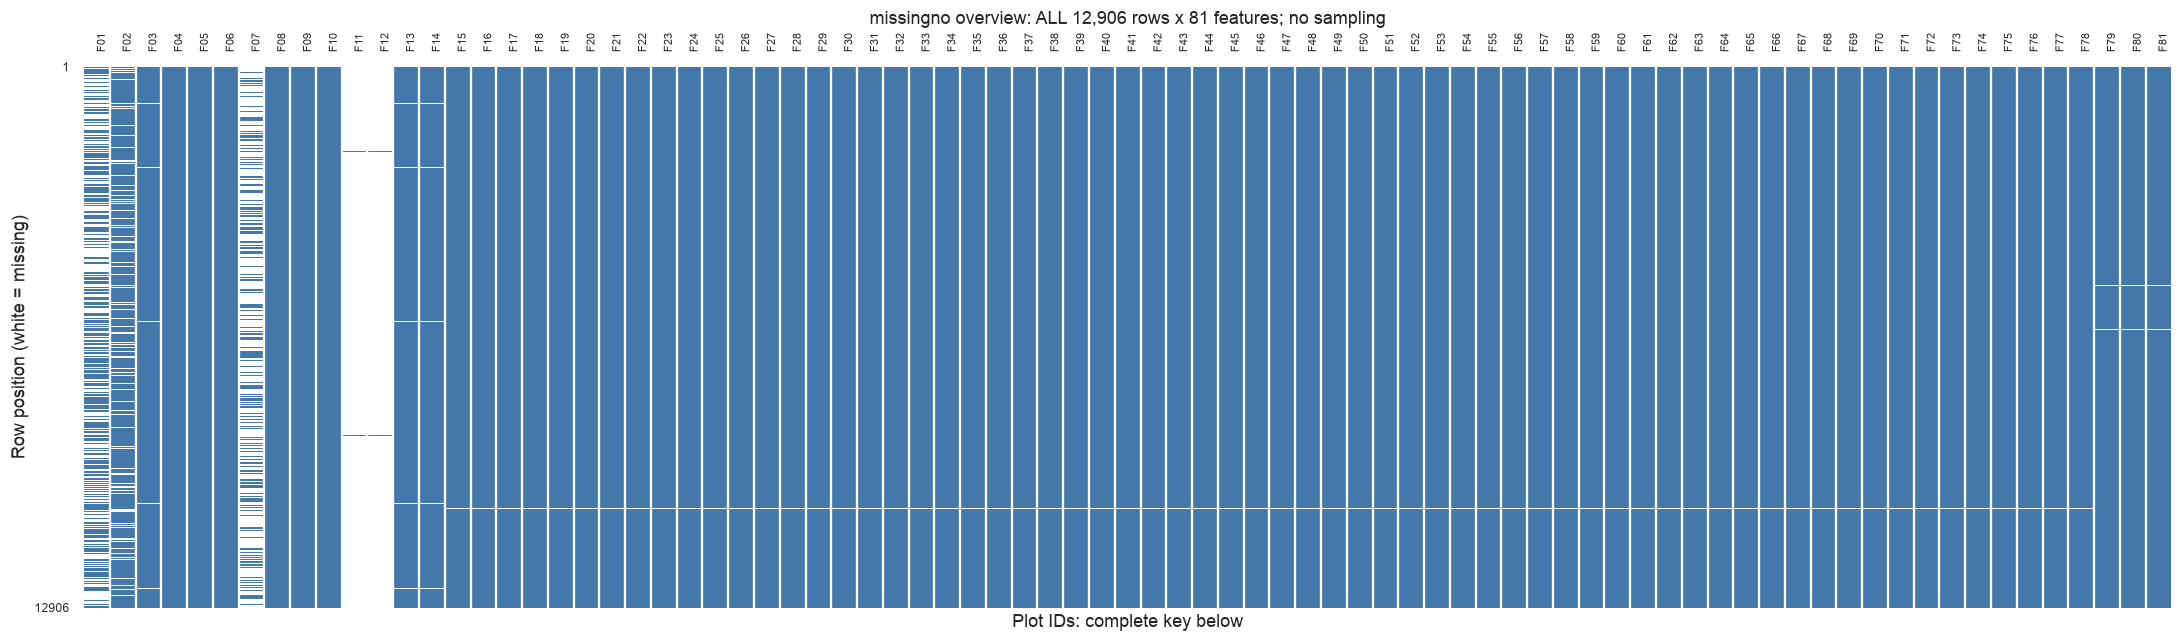

plot_id,feature
F01,patient_race
F02,payer_type
F03,patient_state
F04,patient_zip3
F05,patient_age
F06,patient_gender
F07,bmi
F08,breast_cancer_diagnosis_code
F09,breast_cancer_diagnosis_desc
F10,metastatic_cancer_diagnosis_code


missingno version: 0.5.2


In [6]:
missingno_key = pd.DataFrame({"plot_id": [f"F{i+1:02}" for i in range(len(feature_columns))],
                                 "feature": feature_columns})
overview = df[feature_columns].set_axis(missingno_key.plot_id, axis="columns")
fig, ax = plt.subplots(figsize=(20, 6))
msno.matrix(overview, ax=ax, sparkline=False, labels=True, fontsize=7,
            label_rotation=90, color=(0.27, 0.47, 0.67))
ax.set(title=f"missingno overview: ALL {len(df):,} rows x {len(feature_columns)} features; no sampling",
       xlabel="Plot IDs: complete key below", ylabel="Row position (white = missing)")
plt.tight_layout()
plt.show()
display(HTML("<details><summary>Complete missingno feature key (F01…F81)</summary>"
             + missingno_key.to_html(index=False) + "</details>"))
print("missingno version:", version("missingno"))


### Little's MCAR reference — age/BMI only, not a global dataset test

H0: missingness is MCAR; H1: it is not MCAR. **MCAR** makes the pattern independent of observed
and unobserved values. **MAR** allows dependence on observed information, conditional on which
missingness does not depend on unobserved values. **MNAR** retains dependence on unobserved
values after conditioning on observed information. Observed data alone generally cannot
distinguish MAR from MNAR; failure to reject is not proof of MCAR.

**Scope:** `patient_age`, `bmi` are the two individual numerical measurements identified here.
Age is complete; BMI is documented post-metastatic. This is a retrospective recording check,
not approval of BMI as a baseline predictor. Codes/categories and sparse treatment fields are
unsuitable for the Gaussian numerical reference; contextual variables add repeated ZIP values
and compositional dependencies. Full exclusions and diagnostics remain expandable below.

The unchanged NumPy/SciPy helper estimates common Gaussian ML mean/covariance using EM:
\(D^2=\sum_j n_j(\bar x_{j,o}-\hat\mu_o)^T\hat\Sigma_{oo}^{-1}(\bar x_{j,o}-\hat\mu_o)\),
\(df=\sum_j p_j-p\). Its internal expected sufficient statistics are not preprocessing imputation.
No pairwise-covariance substitute, ridge or pseudoinverse is used.

**Interpretation:** report fail-to-reject only under the working reference when p≥.05.
Gaussian/independence calibration is not established, so cohort-wide inference stays **BLOCKED**.
With only BMI incomplete, this mean-pattern statistic reduces to age-mean contrasts across
BMI-recording patterns (verified in code); it cannot check unobserved BMI or every missingness
mechanism. Numerical convergence/positive covariance does not validate assumptions. The
target-indicator Fisher tests answer a different question and do not replace Little's test.

Algorithm checks use a closed form, invariance/invalid-input tests and the published
[naniar reference](https://naniar.njtierney.com/reference/mcar_test.html)
(airquality: 35.1061749, df 14, p=.00141776). No reference data is downloaded during execution.


In [7]:
from src.little_mcar import little_mcar

little_included = ["patient_age", "bmi"]
little_exclusion_groups = pd.DataFrame([
    {"excluded_features": sorted(clinical_review), "reason": "clinical code/text; treatment documented post-metastatic; code timing unverified"},
    {"excluded_features": sorted(geographic_codes | individual_categorical), "reason": "nominal/code variables; Gaussian numerical model inappropriate"},
    {"excluded_features": [c for c in continuous_columns if c not in little_included],
     "reason": "contextual/shared-ZIP numerical variables; dependence and singular/compositional covariance risk"},
    {"excluded_features": [ID, TARGET], "reason": "identifier and outcome; not candidate numerical measurements"},
])
display(HTML("<details><summary>Little: full exclusions and reasons</summary>"
             + little_exclusion_groups.to_html(index=False) + "</details>"))
little_report = {
    "method/library": "Little (1988) mean-pattern statistic; local Gaussian ML/EM; NumPy/SciPy",
    "included_features": little_included,
    "excluded_features/reasons": "Full grouped exclusions shown above; no p-value-driven subset search",
    "n_rows": len(df), "missing_patterns": np.nan, "test_statistic": np.nan,
    "degrees_of_freedom": np.nan, "p_value": np.nan,
    "decision": "BLOCKED: calibrated MCAR inference; Gaussian/independence assumptions unsupported",
    "assumptions": "independent observations; identifiable common Gaussian mean/covariance; chi-square asymptotics",
    "limitations": "age/BMI retrospective scope; post-metastatic BMI; bounded/nonnormal variables; possible ZIP dependence; no global mechanism classification",
}
try:
    little_result = little_mcar(df[little_included].to_numpy(dtype=float))
    little_report.update({"missing_patterns": little_result["missing_patterns"],
                          "test_statistic": little_result["statistic"],
                          "degrees_of_freedom": little_result["degrees_of_freedom"],
                          "p_value": little_result["p_value"],
                          "normal_reference_decision": "reject H0" if little_result["p_value"] < ALPHA else "fail to reject H0",
                          "EM_iterations": little_result["iterations"],
                          "EM_converged": little_result["converged"],
                          "covariance_condition": little_result["covariance_condition"],
                          "covariance_min_eigenvalue": float(np.linalg.eigvalsh(little_result["covariance_ml"]).min())})
    # Analytic reduction for one incomplete variable; no second hypothesis test.
    age_by_bmi_recording = df.groupby(df.bmi.notna())["patient_age"].agg(n_rows="size", age_mean="mean")
    age_by_bmi_recording.index.name = "BMI_recorded_post_metastatic"
    age_mean_quadratic = float((age_by_bmi_recording.n_rows *
        (age_by_bmi_recording.age_mean - df.patient_age.mean())**2).sum() / df.patient_age.var(ddof=0))
    assert np.isclose(age_mean_quadratic, little_result["statistic"], rtol=1e-6, atol=1e-8)
    little_report["age_pattern_closed_form_statistic"] = age_mean_quadratic
except (ValueError, ArithmeticError, RuntimeError, np.linalg.LinAlgError) as error:
    little_report["decision"] = "BLOCKED: " + str(error)
    little_report["normal_reference_decision"] = "NOT TESTABLE"
    little_result = None
core_little_fields = ["included_features", "n_rows", "missing_patterns", "test_statistic",
                      "degrees_of_freedom", "p_value", "normal_reference_decision", "decision"]
with pd.option_context("display.max_colwidth", None):
    display(pd.Series(little_report, name="actual_result").loc[core_little_fields].to_frame())
if little_result is not None:
    display(HTML(
        "<details><summary>Little: complete report, covariance, patterns and closed-form check</summary>"
        + pd.Series(little_report, name="actual_result").to_frame().to_html()
        + pd.DataFrame(little_result["covariance_ml"], index=little_included, columns=little_included).to_html()
        + pd.DataFrame(little_result["pattern_details"]).to_html(index=False)
        + age_by_bmi_recording.to_html() + "</details>"
    ))
    display(Markdown(
        f"**Computed reference:** D²={little_result['statistic']:.6f}, "
        f"df={little_result['degrees_of_freedom']}, p={little_result['p_value']:.6g}; "
        f"**{little_report['normal_reference_decision']}** at alpha={ALPHA}. "
        "This is conditional on the working reference model, not an established MCAR mechanism. "
        "The formal cohort-wide conclusion remains **BLOCKED** by calibration/scope limitations. "
        "Existing missing-by-target Fisher tests are different questions and do not replace Little's test."
    ))


excluded_features,reason
"[breast_cancer_diagnosis_code, breast_cancer_diagnosis_desc, metastatic_cancer_diagnosis_code, metastatic_first_novel_treatment, metastatic_first_novel_treatment_type]",clinical code/text; treatment documented post-metastatic; code timing unverified
"[Division, Region, patient_gender, patient_race, patient_state, patient_zip3, payer_type]",nominal/code variables; Gaussian numerical model inappropriate
"[population, density, age_median, age_under_10, age_10_to_19, age_20s, age_30s, age_40s, age_50s, age_60s, age_70s, age_over_80, male, female, married, divorced, never_married, widowed, family_size, family_dual_income, income_household_median, income_household_under_5, income_household_5_to_10, income_household_10_to_15, income_household_15_to_20, income_household_20_to_25, income_household_25_to_35, income_household_35_to_50, income_household_50_to_75, income_household_75_to_100, income_household_100_to_150, income_household_150_over, income_household_six_figure, income_individual_median, home_ownership, housing_units, home_value, rent_median, rent_burden, education_less_highschool, education_highschool, education_some_college, education_bachelors, education_graduate, education_college_or_above, education_stem_degree, labor_force_participation, unemployment_rate, self_employed, farmer, race_white, race_black, race_asian, race_native, race_pacific, race_other, race_multiple, hispanic, disabled, poverty, limited_english, commute_time, health_uninsured, veteran, Ozone, PM25, N02]",contextual/shared-ZIP numerical variables; dependence and singular/compositional covariance risk
"[patient_id, DiagPeriodL90D]",identifier and outcome; not candidate numerical measurements


,actual_result
included_features,"[patient_age, bmi]"
n_rows,12906
missing_patterns,2
test_statistic,3.506534
degrees_of_freedom,1
p_value,0.061127
normal_reference_decision,fail to reject H0
decision,BLOCKED: calibrated MCAR inference; Gaussian/independence assumptions unsupported


,actual_result
method/library,Little (1988) mean-pattern statistic; local Gaussian ML/EM; NumPy/SciPy
included_features,"[patient_age, bmi]"
excluded_features/reasons,Full grouped exclusions shown above; no p-value-driven subset search
n_rows,12906
missing_patterns,2
test_statistic,3.506534
degrees_of_freedom,1
p_value,0.061127
decision,BLOCKED: calibrated MCAR inference; Gaussian/independence assumptions unsupported
assumptions,independent observations; identifiable common Gaussian mean/covariance; chi-square asymptotics


**Computed reference:** D²=3.506534, df=1, p=0.0611272; **fail to reject H0** at alpha=0.05. This is conditional on the working reference model, not an established MCAR mechanism. The formal cohort-wide conclusion remains **BLOCKED** by calibration/scope limitations. Existing missing-by-target Fisher tests are different questions and do not replace Little's test.

### Supplementary: why no wider Little test is run

Four scopes are screened without extra p-values: age/BMI; age/BMI + household median income
+ PM25; all 69 numerical candidates; and 67 contextual variables at one record per ZIP3.
Complete-case correlation rank/condition diagnose numerical dependencies, not Gaussianity or
independence; they are not Little's ML covariance or a fitted scaler. Rank depends on tolerance.
ZIP aggregation requires invariant observed values **and** missing masks and changes the estimand.

The full four-scope table remains expandable. Sparse patterns, repeated context and covariance
dependencies do not establish better calibration; distinct ZIPs need not be independent.
There is no universal Little-test “five per cell” rule. Retain the primary reference/BLOCKED
inference: no pattern deletion, p-value search or MAR/MNAR assignment is justified.


In [8]:
contextual_columns = [c for c in continuous_columns if c not in individual_numeric]
context_value_variation = df.groupby("patient_zip3")[contextual_columns].nunique()
context_mask_variation = df[contextual_columns].isna().groupby(df.patient_zip3).nunique()
value_conflicts = int(context_value_variation.gt(1).any().sum())
mask_conflicts = int(context_mask_variation.gt(1).any().sum())
print("Contextual numerical columns:", len(contextual_columns))
print("Columns with within-ZIP observed-value / missing-mask conflicts:", value_conflicts, mask_conflicts)

# Read-only feasibility views; neither a model feature set nor a cleaned dataset.
scope_views = [
    ("Primary age/BMI", "patient record", df[little_included],
     "PRIMARY REFERENCE; inference BLOCKED", "Individual recording; bounded/nonnormal measurements, independence unsupported"),
    ("Age/BMI + income + PM25", "patient record",
     df[["patient_age", "bmi", "income_household_median", "PM25"]],
     "NOT RUN", "Shared ZIP context and sparse patterns; full covariance rank would not repair calibration"),
    ("All numerical candidates", "patient record", df[continuous_columns],
     "NOT RUN", "Repeated context, compositional dependencies and weakly supported patterns"),
]
if value_conflicts == 0 and mask_conflicts == 0:
    context_by_zip = df.groupby("patient_zip3")[contextual_columns].first()
    scope_views.append(("Contextual variables by ZIP", "ZIP3", context_by_zip,
                        "NOT RUN", "Different estimand; few incomplete ZIPs, dependencies and possible spatial correlation"))
else:
    print("ZIP scope BLOCKED: no arbitrary first-value aggregation of inconsistent values/masks.")

scope_records = []
for name, unit, values, status, reason in scope_views:
    pattern_sizes = values.isna().value_counts(dropna=False)
    complete = values.loc[values.notna().all(axis=1)]
    rank, condition = np.nan, np.nan
    if len(complete) > values.shape[1] and complete.nunique().gt(1).all():
        complete_correlation = complete.corr().to_numpy()
        rank = int(np.linalg.matrix_rank(complete_correlation))
        condition = float(np.linalg.cond(complete_correlation))
    scope_records.append({
        "scope": name, "unit": unit, "n_rows": len(values), "n_features": values.shape[1],
        "missing_patterns": len(pattern_sizes), "pattern_sizes_desc": pattern_sizes.to_list(),
        "complete_n": len(complete), "CC_correlation_rank": rank,
        "CC_correlation_condition": condition, "test_status": status, "reason": reason,
    })
scope_feasibility = pd.DataFrame(scope_records).set_index("scope")
display(HTML("<details><summary>Supplement: all four Little-scope feasibility screens</summary>"
             + scope_feasibility.to_html() + "</details>"))
display(Markdown(
    f"**Scope check:** {len(contextual_columns)} contextual variables; within-ZIP value/mask "
    f"conflicts={value_conflicts}/{mask_conflicts}. Adding context does not establish valid calibration."
))
print("Additional Little tests run: 0; primary statistic and BLOCKED inference retained.")


Contextual numerical columns: 67
Columns with within-ZIP observed-value / missing-mask conflicts: 0 0


,unit,n_rows,n_features,missing_patterns,pattern_sizes_desc,complete_n,CC_correlation_rank,CC_correlation_condition,test_status,reason
scope,,,,,,,,,,
Primary age/BMI,patient record,12906,2,2,"[8965, 3941]",3941,2,1.136489e+00,PRIMARY REFERENCE; inference BLOCKED,"Individual recording; bounded/nonnormal measurements, independence unsupported"
Age/BMI + income + PM25,patient record,12906,4,5,"[8940, 3933, 21, 8, 4]",3933,4,1.281887e+00,NOT RUN,Shared ZIP context and sparse patterns; full covariance rank would not repair calibration
All numerical candidates,patient record,12906,69,6,"[8940, 3933, 21, 8, 3, 1]",3933,67,1.102092e+16,NOT RUN,"Repeated context, compositional dependencies and weakly supported patterns"
Contextual variables by ZIP,ZIP3,739,67,4,"[731, 6, 1, 1]",731,65,2.972556e+16,NOT RUN,"Different estimand; few incomplete ZIPs, dependencies and possible spatial correlation"


**Scope check:** 67 contextual variables; within-ZIP value/mask conflicts=0/0. Adding context does not establish valid calibration.

Additional Little tests run: 0; primary statistic and BLOCKED inference retained.


### Literal tokens versus confirmed missing values

A second **read-only lexical read** preserves blanks and common candidate tokens that pandas
may already interpret as NA. The token set is deliberately a generic review list, **not** a WiDS
sentinel dictionary. Values such as `999` may be legitimate measurements or codes. Matching a
candidate does not establish missingness; no replacement or clinical interpretation follows.

In [9]:
lexical = pd.read_csv(DATA_PATH, dtype="string", keep_default_na=False)
candidate_tokens = {"", "na", "n/a", "nan", "null", "none", "unknown", "missing", "?", "-9", "-99", "-999", "999", "9999"}
sentinel_records = []
for column in feature_columns:
    counts = lexical[column].str.strip().str.casefold().value_counts()
    for token, count in counts[counts.index.isin(candidate_tokens)].items():
        sentinel_records.append({"feature": column, "literal_token": "[empty field]" if token == "" else token,
                                 "count": int(count),
                                 "status": ("identifier token retained; not classified as missing"
                                            if column in geographic_codes and token != ""
                                            else "candidate only; unverified")})
sentinel_review = pd.DataFrame(sentinel_records, columns=["feature", "literal_token", "count", "status"])
display(sentinel_review.sort_values("count", ascending=False).head(20))
nonblank_matches = sentinel_review.loc[sentinel_review.literal_token != "[empty field]"]
print("Nonempty candidate-token matches across columns:", int(nonblank_matches['count'].sum()))
display(nonblank_matches)
assert df.patient_zip3.eq("999").sum() == zip_literal_999_n
print("The literal ZIP code 999 remains observed; no missing-value replacement was made.")
print("Twenty largest token/column counts shown. Absence from this list does not verify other codes.")

,feature,literal_token,count,status
6,metastatic_first_novel_treatment_type,[empty field],12882,candidate only; unverified
5,metastatic_first_novel_treatment,[empty field],12882,candidate only; unverified
4,bmi,[empty field],8965,candidate only; unverified
0,patient_race,[empty field],6385,candidate only; unverified
1,payer_type,[empty field],1803,candidate only; unverified
7,Region,[empty field],52,candidate only; unverified
8,Division,[empty field],52,candidate only; unverified
2,patient_state,[empty field],51,candidate only; unverified
31,income_household_5_to_10,[empty field],4,candidate only; unverified
40,income_household_150_over,[empty field],4,candidate only; unverified


Nonempty candidate-token matches across columns: 1


,feature,literal_token,count,status
3,patient_zip3,999,1,identifier token retained; not classified as m...


The literal ZIP code 999 remains observed; no missing-value replacement was made.
Twenty largest token/column counts shown. Absence from this list does not verify other codes.


## 5. Numerical distributions and preliminary outlier exploration

**Questions:** how dispersed or skewed are appropriate numerical candidates, and which values
merit later domain review? Summary statistics ignore missing observations and show their own
observed counts. Six columns are shown for semantic breadth rather than a significance-screening rule;
dictionary-supported units are labeled where available; other units remain unverified. Context distributions are **patient-weighted**, so large patient
clusters can repeat the same area-level value.

Pandas' sample skewness uses its bias-corrected convention and omits missing values. It is
sensitive to sample size and extreme observations, not a requirement to transform data. Tukey fences
`Q1 − 1.5 × IQR` and `Q3 + 1.5 × IQR` flag unusual observations relative to each empirical
marginal distribution. Flags are **not** confirmed errors, clinical cutoffs, or instructions to
remove/winsorize records. A zero IQR makes this simple diagnostic unsuitable and is marked explicitly.

,count,mean,std,min,25%,50%,75%,max,missing_pct,sample_skewness
patient_age,12906.0,59.183,13.335,18.000,50.000,59.000,67.000,91.000,0.000,0.128
bmi,3941.0,28.985,5.697,14.000,24.660,28.190,32.920,85.000,69.464,0.737
population,12905.0,20744.441,13886.904,635.545,9463.897,19154.190,30021.279,71374.132,0.008,0.998
density,12905.0,1581.950,2966.305,0.917,171.857,700.338,1666.515,21172.000,0.008,4.040
age_median,12905.0,40.502,4.037,20.600,37.130,40.639,42.935,54.570,0.008,0.294
age_under_10,12905.0,11.123,1.512,0.000,10.160,11.039,12.190,17.675,0.008,-0.110
age_10_to_19,12905.0,12.945,1.924,6.314,11.741,12.924,14.020,35.300,0.008,1.257
age_20s,12905.0,13.290,3.354,5.925,11.013,12.538,14.971,62.100,0.008,2.117
age_30s,12905.0,12.862,2.325,1.500,11.292,12.443,14.027,25.471,0.008,0.955
age_40s,12905.0,12.067,1.248,0.800,11.340,12.124,12.892,17.820,0.008,-0.326


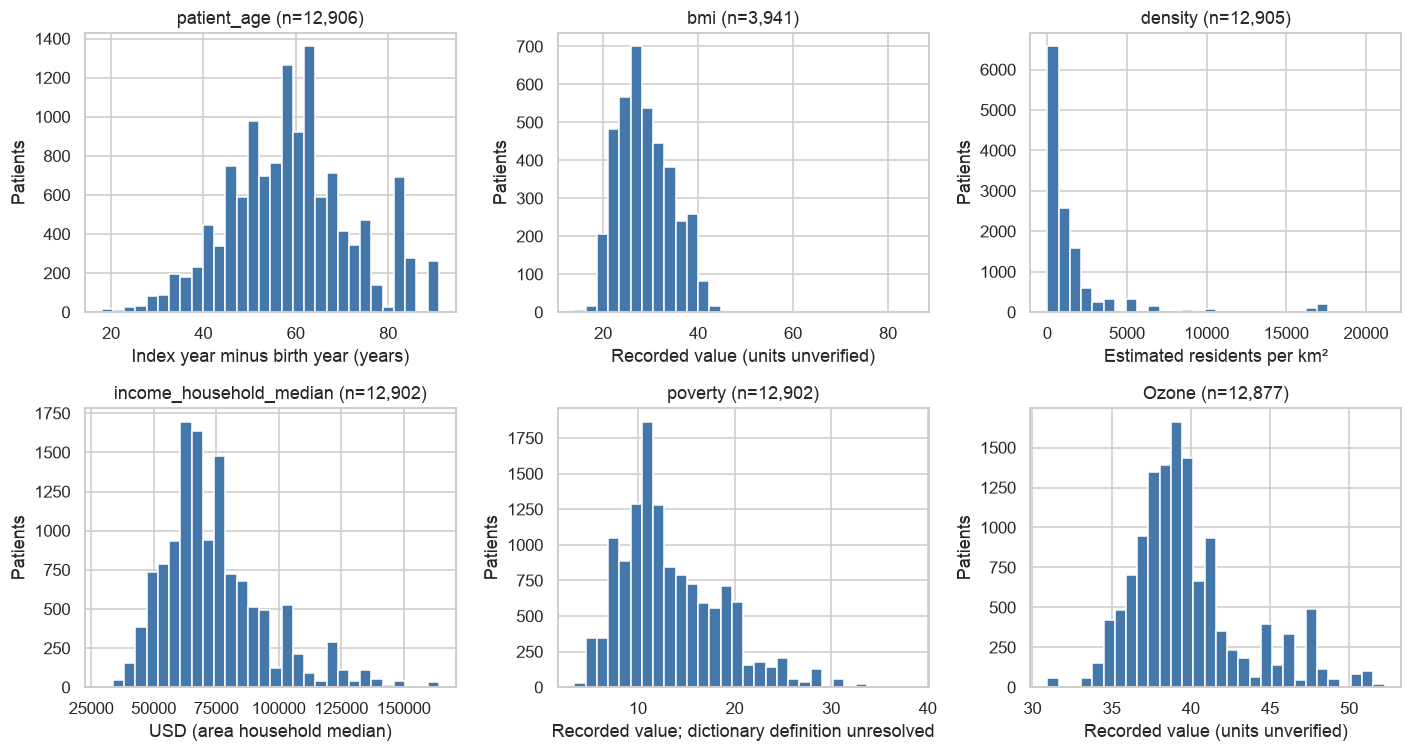

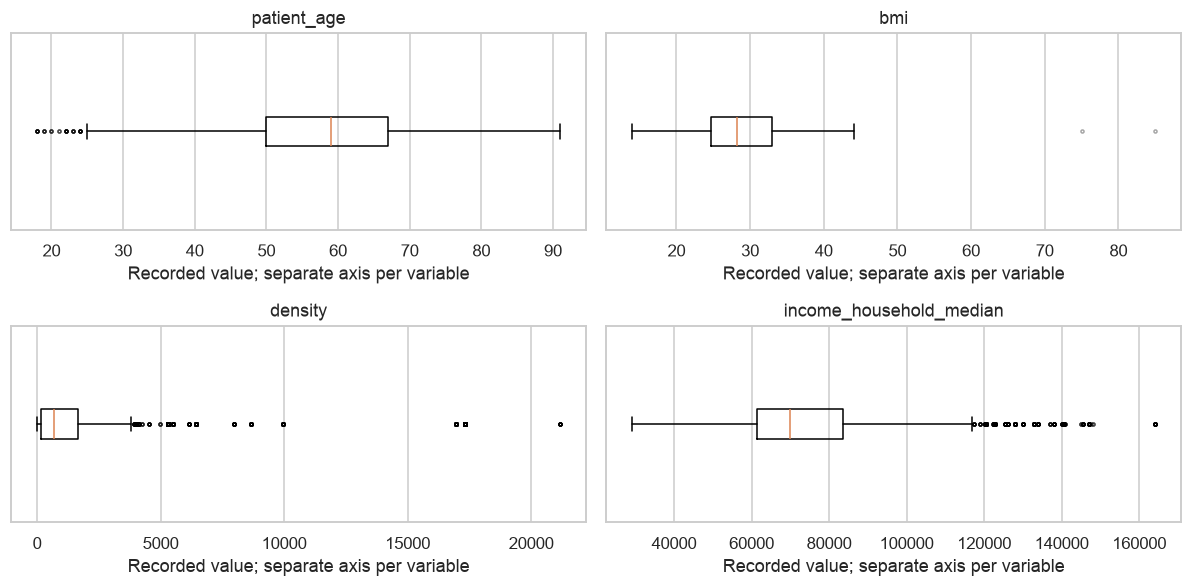

,observed_n,IQR,lower_fence,upper_fence,flagged_n,flagged_pct_observed,diagnostic_status
feature,,,,,,,
race_native,12905,0.577,-0.653,1.656,1246,9.655,assessed
Ozone,12877,3.438,32.542,46.293,1194,9.272,assessed
farmer,12902,2.273,-3.367,5.726,1178,9.130,assessed
race_asian,12905,5.970,-7.859,16.022,1159,8.981,assessed
home_value,12902,238121.796,-189422.239,763064.943,1148,8.898,assessed
limited_english,12902,4.982,-6.478,13.448,1130,8.758,assessed
density,12905,1494.658,-2070.130,3908.503,1092,8.462,assessed
race_pacific,12905,0.123,-0.160,0.330,1027,7.958,assessed
race_other,12905,6.604,-8.592,17.824,846,6.556,assessed


**Observed:** density skewness is **4.04**, versus **0.13** for patient age. BMI ranges from **14.00** to **85.00** among observed records; **2** observed BMI values exceed the empirical Tukey fences. Right tails motivate later sensitivity checks, not automatic log transforms or deletion. No clinical plausibility verdict is possible without verified units and source records.

In [10]:
numerical_summary = df[continuous_columns].describe(percentiles=[0.25, 0.5, 0.75]).T
numerical_summary["missing_pct"] = df[continuous_columns].isna().mean() * 100
numerical_summary["sample_skewness"] = df[continuous_columns].skew()
display(HTML("<details><summary>Supplement: complete numerical summary for all candidates</summary>"
             + numerical_summary.round(3).to_html() + "</details>"))

numerical_focus = ["patient_age", "bmi", "density", "income_household_median", "poverty", "Ozone"]
plot_units = {"patient_age": "Index year minus birth year (years)",
              "density": "Estimated residents per km²", "income_household_median": "USD (area household median)",
              "poverty": "Recorded value; dictionary definition unresolved"}
fig, axes = plt.subplots(2, 3, figsize=(13, 7))
for ax, column in zip(axes.flat, numerical_focus):
    values = df.loc[df[column].notna(), column]
    ax.hist(values, bins=30, color="#4477AA", edgecolor="white")
    ax.set(title=f"{column} (n={len(values):,})", xlabel=plot_units.get(column, "Recorded value (units unverified)"), ylabel="Patients")
plt.tight_layout()
plt.show()

box_focus = ["patient_age", "bmi", "density", "income_household_median"]
fig, axes = plt.subplots(2, 2, figsize=(11, 5.5))
for ax, column in zip(axes.flat, box_focus):
    values = df.loc[df[column].notna(), column]
    ax.boxplot(values, orientation="horizontal", flierprops={"markersize": 2, "alpha": 0.35})
    ax.set(title=column, xlabel="Recorded value; separate axis per variable", yticks=[])
plt.tight_layout()
plt.show()

outlier_records = []
for column in continuous_columns:
    values = df.loc[df[column].notna(), column]
    q1, q3 = values.quantile([0.25, 0.75])
    iqr = q3 - q1
    lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    flagged_n = int(((values < lower) | (values > upper)).sum()) if iqr > 0 else np.nan
    outlier_records.append({"feature": column, "observed_n": len(values), "IQR": iqr,
                            "lower_fence": lower, "upper_fence": upper,
                            "flagged_n": flagged_n,
                            "flagged_pct_observed": flagged_n/len(values)*100 if len(values) else np.nan,
                            "diagnostic_status": "assessed" if iqr > 0 else "not assessed: zero/undefined IQR"})
outlier_review = pd.DataFrame(outlier_records).set_index("feature")
display(outlier_review.sort_values("flagged_pct_observed", ascending=False).head(12).round(3))
display(Markdown(
    f"**Observed:** density skewness is **{numerical_summary.loc['density', 'sample_skewness']:.2f}**, "
    f"versus **{numerical_summary.loc['patient_age', 'sample_skewness']:.2f}** for patient age. "
    f"BMI ranges from **{numerical_summary.loc['bmi', 'min']:.2f}** to "
    f"**{numerical_summary.loc['bmi', 'max']:.2f}** among observed records; "
    f"**{outlier_review.loc['bmi', 'flagged_n']:.0f}** observed BMI values exceed the empirical Tukey fences. "
    "Right tails motivate later sensitivity checks, not automatic log transforms or deletion. "
    "No clinical plausibility verdict is possible without verified units and source records."
))

### Required normality tests across every numerical candidate

H0: observed values follow a normal distribution; H1: they do not. Per-feature nonmissing n
determines Shapiro–Wilk (3≤n≤5000) or D’Agostino–Pearson (n>5000), at α=.05. Insufficient data,
nonfinite values, constants or invalid results are NOT TESTABLE with reasons. Only that
feature's NaNs are omitted; the training frame is unchanged. All69 results remain displayed.

Read each row's **decision** as: `reject H0` = evidence against marginal normality;
`fail to reject H0` = insufficient evidence to reject, **not proof of normality**.
Small p-values do not measure the size of departure. Raw per-feature decisions do not control
family-wide error across 69 tests. Large n, bounded/discrete variables, selected observed cases
and repeated ZIP context limit iid calibration; marginal tests do not establish joint normality.

The five-row scaling roadmap uses observed ranges/skewness/IQR flags, not p-values alone.
StandardScaler changes location/scale, not shape; Min-Max and Robust scaling also do not create
Gaussianity. Quantile transforms change geometry. No scaler is selected/fitted; compare the
required families for the downstream estimator using training folds only. BMI timing remains a gate.

[Shapiro](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.shapiro.html) /
[normaltest](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.normaltest.html):
for normaltest's χ²(2) reference, log(p)=−statistic/2 stays finite when p underflows. Underflow
is flagged, not presented as exact-zero probability; Shapiro log(p) uses its returned probability.


In [11]:
normality_records = []
for column in continuous_columns:
    values = df.loc[df[column].notna(), column].to_numpy(dtype=float)
    n_observed = len(values)
    record = {"feature": column, "n_observed": n_observed,
              "missing_pct": df[column].isna().mean() * 100,
              "test_name": "NOT TESTABLE", "statistic": np.nan, "p_value": np.nan,
              "decision": "NOT TESTABLE", "log_p_value": np.nan, "limitations": "iid calibration; marginal observed cases only"}
    reason = None
    if n_observed < 3:
        reason = "fewer than 3 observed values"
    elif not np.isfinite(values).all():
        reason = "non-finite observed values; not silently removed"
    elif np.ptp(values) == 0:
        reason = "zero observed variance"
    if reason is None:
        record["test_name"] = "Shapiro-Wilk" if n_observed <= 5000 else "D'Agostino-Pearson"
        try:
            with warnings.catch_warnings(record=True) as caught:
                warnings.simplefilter("always")
                result = stats.shapiro(values) if n_observed <= 5000 else stats.normaltest(values)
            if not np.isfinite(result.statistic) or not np.isfinite(result.pvalue) or not 0 <= result.pvalue <= 1:
                raise ArithmeticError("invalid statistic/probability")
            # normaltest uses a chi-square reference with df=2: log survival = -K2/2.
            # Preserve SciPy's raw probability, but do not print an underflow as exact zero.
            log_p = (-0.5 * float(result.statistic) if n_observed > 5000
                     else float(np.log(result.pvalue)) if result.pvalue > 0 else -np.inf)
            record.update(statistic=float(result.statistic), p_value=float(result.pvalue), log_p_value=log_p,
                          decision="reject H0" if result.pvalue < ALPHA else "fail to reject H0")
            if caught:
                record["limitations"] += "; " + "; ".join(str(w.message) for w in caught)
            if result.pvalue == 0:
                record["limitations"] += "; p underflow: returned 0 is not an exact zero probability"
        except (ValueError, ArithmeticError, FloatingPointError) as error:
            reason = str(error)
    if reason:
        record["decision"] = "NOT TESTABLE"
        record["limitations"] = reason
    normality_records.append(record)
normality_table = pd.DataFrame(normality_records).set_index("feature")
assert len(normality_table) == len(continuous_columns)
with pd.option_context("display.max_rows", None):
    display(normality_table.style.format({"missing_pct": "{:.3f}", "statistic": "{:.6g}", "p_value": lambda p: "UNDERFLOW (see log_p)" if p == 0 else f"{p:.4e}", "log_p_value": "{:.4f}"}))
normality_counts = normality_table.decision.value_counts().reindex(
    ["reject H0", "fail to reject H0", "NOT TESTABLE"], fill_value=0)
display(normality_counts.rename("feature_count").to_frame())
display(normality_table.test_name.value_counts().rename("feature_count").to_frame())
# Recommendations use earlier descriptive outputs; no new test or transform is run.
scaling_records = []
for column, candidates, rationale, limitations in [
    ("patient_age", "StandardScaler or MinMaxScaler",
     "Compare estimator sensitivity to age scale; inspect bounded/discrete support, not just rejection",
     "Index-year age and prospective availability need review; affine scaling does not change shape"),
    ("bmi", "If retrospective use is allowed: StandardScaler versus RobustScaler",
     "Observed-case skew/extremes motivate a median/IQR comparison, not an automatic choice",
     "Post-metastatic: blocked for earlier baseline; heavy missingness selects the observed sample"),
    ("density", "Standard / Robust; QuantileTransformer (uniform and normal)",
     "Observed right tail and extreme-value flags motivate sensitivity to tails/rank geometry",
     "Repeated area values; quantile ties/interpretation; check zero IQR and eligible reference period"),
    ("income_household_median", "Standard / Robust; QuantileTransformer (uniform and normal)",
     "Compare effects of monetary scale and observed skew on a scale-sensitive estimator",
     "Area-level, not personal income; reference year and training-fold support matter"),
]:
    summary = numerical_summary.loc[column]
    flags = outlier_review.loc[column]
    scaling_records.append({
        "Feature/group": column,
        "Observed distribution characteristics": (
            f"n={int(summary['count'])}; range={summary['min']:.2f}…{summary['max']:.2f}; "
            f"skew={summary['sample_skewness']:.2f}; IQR flags={int(flags.flagged_n)}/{int(flags.observed_n)}; "
            f"{normality_table.loc[column, 'decision']}"),
        "Candidate scaling methods": candidates, "Scientific rationale": rationale, "Limitations": limitations,
    })
proportion_columns = ["male", "female", "education_college_or_above", "income_household_six_figure"]
proportion_summary = numerical_summary.loc[proportion_columns]
scaling_records.append({
    "Feature/group": "Documented area proportions (four examples)",
    "Observed distribution characteristics": (
        f"{', '.join(proportion_columns)}; observed range across columns "
        f"{proportion_summary['min'].min():.2f}…{proportion_summary['max'].max():.2f}; "
        f"skew range={proportion_summary.sample_skewness.min():.2f}…{proportion_summary.sample_skewness.max():.2f}; "
        f"reject H0={normality_table.loc[proportion_columns, 'decision'].eq('reject H0').sum()}/{len(proportion_columns)}"),
    "Candidate scaling methods": "StandardScaler / MinMaxScaler; retain original percent scale as a comparison",
    "Scientific rationale": "Bounded percentages need not be Gaussian; compare scale-sensitive geometry without assuming normality",
    "Limitations": "Shared/compositional context; Min-Max depends on training extrema; rank transforms alter meaning",
})
scaling_candidates = pd.DataFrame(scaling_records)
display(scaling_candidates.style.hide(axis="index").set_properties(**{
    "text-align": "left", "vertical-align": "top", "white-space": "normal", "max-width": "19em"
}))
display(Markdown(
    f"**Observed normality-reference decisions:** {normality_counts['reject H0']} reject, "
    f"{normality_counts['fail to reject H0']} fail to reject, {normality_counts['NOT TESTABLE']} not testable. "
    "These results motivate controlled comparisons of the listed methods, not an automatic scaler choice."
))

print("Raw SciPy p-value underflows:", int(normality_table.p_value.eq(0).sum()), "; inspect log_p_value, not literal zero probabilities.")


,n_observed,missing_pct,test_name,statistic,p_value,decision,log_p_value,limitations
feature,,,,,,,,
patient_age,12906,0.000,D'Agostino-Pearson,42.1018,7.2063e-10,reject H0,-21.0509,iid calibration; marginal observed cases only
bmi,3941,69.464,Shapiro-Wilk,0.960251,1.4273e-31,reject H0,-71.0244,iid calibration; marginal observed cases only
population,12905,0.008,D'Agostino-Pearson,1895.31,UNDERFLOW (see log_p),reject H0,-947.6541,iid calibration; marginal observed cases only; p underflow: returned 0 is not an exact zero probability
density,12905,0.008,D'Agostino-Pearson,10620.8,UNDERFLOW (see log_p),reject H0,-5310.3995,iid calibration; marginal observed cases only; p underflow: returned 0 is not an exact zero probability
age_median,12905,0.008,D'Agostino-Pearson,189.63,6.6443e-42,reject H0,-94.8148,iid calibration; marginal observed cases only
age_under_10,12905,0.008,D'Agostino-Pearson,305.847,3.8555e-67,reject H0,-152.9237,iid calibration; marginal observed cases only
age_10_to_19,12905,0.008,D'Agostino-Pearson,4315.48,UNDERFLOW (see log_p),reject H0,-2157.7399,iid calibration; marginal observed cases only; p underflow: returned 0 is not an exact zero probability
age_20s,12905,0.008,D'Agostino-Pearson,6772.6,UNDERFLOW (see log_p),reject H0,-3386.2980,iid calibration; marginal observed cases only; p underflow: returned 0 is not an exact zero probability
age_30s,12905,0.008,D'Agostino-Pearson,1847.1,UNDERFLOW (see log_p),reject H0,-923.5501,iid calibration; marginal observed cases only; p underflow: returned 0 is not an exact zero probability


,feature_count
decision,
reject H0,69
fail to reject H0,0
NOT TESTABLE,0


,feature_count
test_name,
D'Agostino-Pearson,68
Shapiro-Wilk,1


Feature/group,Observed distribution characteristics,Candidate scaling methods,Scientific rationale,Limitations
patient_age,n=12906; range=18.00…91.00; skew=0.13; IQR flags=44/12906; reject H0,StandardScaler or MinMaxScaler,"Compare estimator sensitivity to age scale; inspect bounded/discrete support, not just rejection",Index-year age and prospective availability need review; affine scaling does not change shape
bmi,n=3941; range=14.00…85.00; skew=0.74; IQR flags=2/3941; reject H0,If retrospective use is allowed: StandardScaler versus RobustScaler,"Observed-case skew/extremes motivate a median/IQR comparison, not an automatic choice",Post-metastatic: blocked for earlier baseline; heavy missingness selects the observed sample
density,n=12905; range=0.92…21172.00; skew=4.04; IQR flags=1092/12905; reject H0,Standard / Robust; QuantileTransformer (uniform and normal),Observed right tail and extreme-value flags motivate sensitivity to tails/rank geometry,Repeated area values; quantile ties/interpretation; check zero IQR and eligible reference period
income_household_median,n=12902; range=29222.00…164119.18; skew=1.11; IQR flags=703/12902; reject H0,Standard / Robust; QuantileTransformer (uniform and normal),Compare effects of monetary scale and observed skew on a scale-sensitive estimator,"Area-level, not personal income; reference year and training-fold support matter"
Documented area proportions (four examples),"male, female, education_college_or_above, income_household_six_figure; observed range across columns 5.69…77.82; skew range=-0.77…0.77; reject H0=4/4",StandardScaler / MinMaxScaler; retain original percent scale as a comparison,Bounded percentages need not be Gaussian; compare scale-sensitive geometry without assuming normality,Shared/compositional context; Min-Max depends on training extrema; rank transforms alter meaning


**Observed normality-reference decisions:** 69 reject, 0 fail to reject, 0 not testable. These results motivate controlled comparisons of the listed methods, not an automatic scaler choice.

Raw SciPy p-value underflows: 39 ; inspect log_p_value, not literal zero probabilities.


## 6. Categorical distributions, cardinality, and rare values

Report levels/support among **nonmissing** observations; missingness is separate. This includes
ZIP and diagnosis/treatment codes, irrespective of numeric-looking storage. Plots show at most
ten levels with coverage; no unseen level is recoded.

The diagnostic `<1%` rule is not a pooling decision: at high cardinality even uniform levels
can all satisfy it. ZIP support `<5` and `<20` provides an absolute-count comparison, not a
chi-square rule. Learn any later grouping/encoding in training folds and handle unknown levels.
Rare examples remain expandable; exact code meanings and ZIP validity are not inferred.


,observed_n,missing_n,cardinality,largest_level_pct_observed,rare_levels_lt_1pct,rows_in_rare_levels,rare_rows_pct_observed
feature,,,,,,,
patient_zip3,12906,0,739,1.852,733,11892,92.143
patient_state,12855,51,50,18.965,29,1228,9.553
breast_cancer_diagnosis_code,12906,0,50,15.357,32,815,6.315
breast_cancer_diagnosis_desc,12906,0,50,15.357,32,815,6.315
metastatic_cancer_diagnosis_code,12906,0,43,54.641,31,626,4.850
Division,12854,52,9,22.740,1,5,0.039
patient_race,6521,6385,5,55.022,0,0,0.000
Region,12854,52,4,30.489,0,0,0.000
payer_type,11103,1803,3,54.328,0,0,0.000


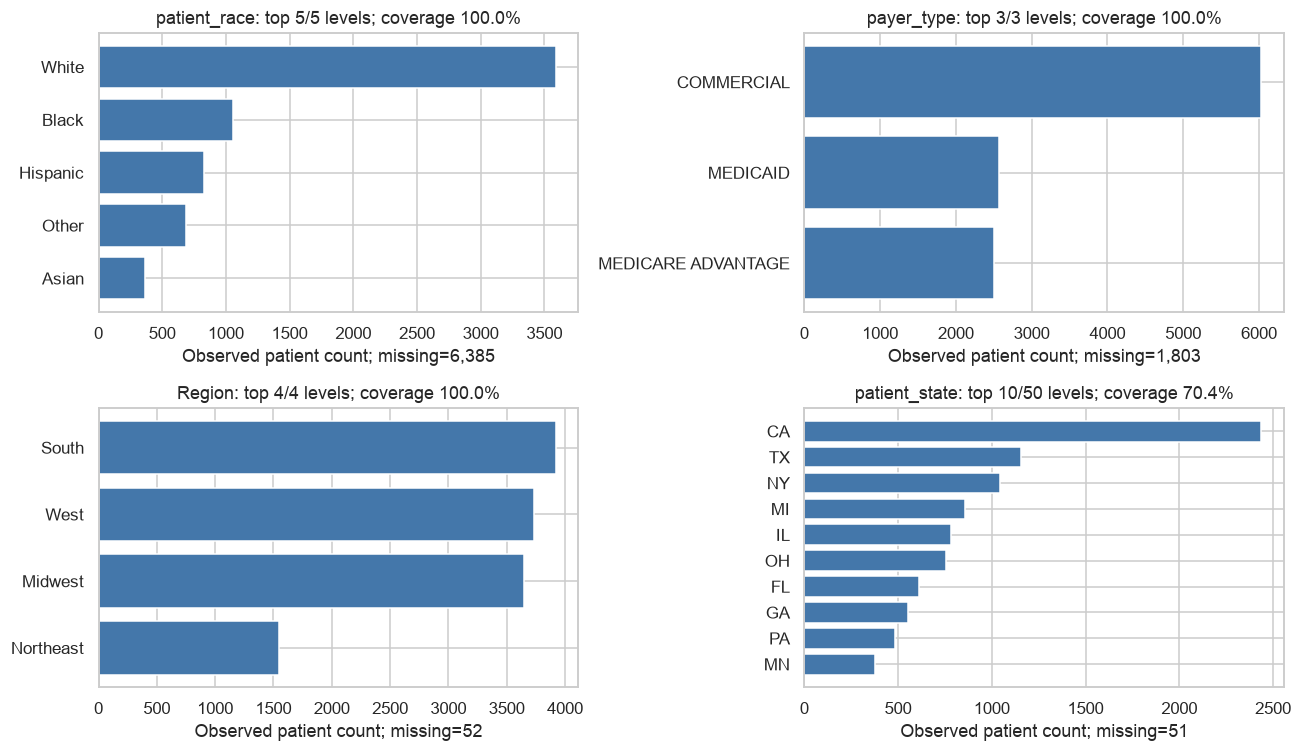

,flagged_levels,flagged_levels_pct,patients_in_flagged_levels,patients_pct
diagnostic_rule,,,,
share < 1%,733,99.188,11892,92.143
count < 5,201,27.199,470,3.642
count < 20,549,74.290,3972,30.776


Uniform share at this cardinality: 0.135% per ZIP.


feature,literal_level,patients,pct_observed
patient_zip3,163,1,0.0077
patient_zip3,678,1,0.0077
patient_zip3,162,1,0.0077
patient_zip3,664,1,0.0077
patient_zip3,149,1,0.0077
breast_cancer_diagnosis_code,C50421,1,0.0077
breast_cancer_diagnosis_code,1759,1,0.0077
breast_cancer_diagnosis_code,C50,1,0.0077
breast_cancer_diagnosis_code,C5031,1,0.0077
breast_cancer_diagnosis_code,C50021,1,0.0077


**Observed:** ZIP has **739** categories; **733** fall below the stated 1% threshold. That relative rule covers **92.14%** of patients. In contrast, count <5 flags **201** ZIPs and **3.64%** of patients. The 1% rule would erase most ZIP distinctions; compare support and unknown-level behavior later. No pooling, encoding or disease-code interpretation is performed.

In [12]:
category_records = []
for column in categorical_columns:
    counts = df[column].value_counts()
    shares = counts / counts.sum() if counts.sum() else counts.astype(float)
    rare = counts.loc[shares < RARE_SHARE]
    category_records.append({
        "feature": column, "observed_n": int(counts.sum()), "missing_n": int(df[column].isna().sum()),
        "cardinality": len(counts),
        "largest_level_pct_observed": shares.max() * 100 if len(shares) else np.nan,
        "rare_levels_lt_1pct": len(rare), "rows_in_rare_levels": int(rare.sum()),
        "rare_rows_pct_observed": rare.sum()/counts.sum()*100 if counts.sum() else np.nan,
    })
category_summary = pd.DataFrame(category_records).set_index("feature")
display(category_summary.sort_values("cardinality", ascending=False).round(3))

fig, axes = plt.subplots(2, 2, figsize=(12, 7))
for ax, column in zip(axes.flat, ["patient_race", "payer_type", "Region", "patient_state"]):
    counts = df[column].value_counts()
    shown = counts.head(10).iloc[::-1]
    ax.barh(shown.index.astype(str), shown, color="#4477AA")
    ax.set(title=f"{column}: top {len(shown)}/{len(counts)} levels; coverage {shown.sum()/counts.sum():.1%}",
           xlabel=f"Observed patient count; missing={df[column].isna().sum():,}")
plt.tight_layout()
plt.show()

zip_counts = df.patient_zip3.value_counts()
zip_support_records = []
for rule, mask in [
    ("share < 1%", zip_counts / zip_counts.sum() < RARE_SHARE),
    ("count < 5", zip_counts < 5),
    ("count < 20", zip_counts < 20),
]:
    zip_support_records.append({
        "diagnostic_rule": rule, "flagged_levels": int(mask.sum()),
        "flagged_levels_pct": mask.mean() * 100,
        "patients_in_flagged_levels": int(zip_counts.loc[mask].sum()),
        "patients_pct": zip_counts.loc[mask].sum() / zip_counts.sum() * 100,
    })
zip_support = pd.DataFrame(zip_support_records).set_index("diagnostic_rule")
display(zip_support.round(3))
print(f"Uniform share at this cardinality: {100 / len(zip_counts):.3f}% per ZIP.")

rare_examples = []
for column in ["patient_zip3", "breast_cancer_diagnosis_code", "metastatic_cancer_diagnosis_code"]:
    counts = df[column].value_counts()
    rare_counts = counts.loc[counts / counts.sum() < RARE_SHARE].sort_values()
    for level, count in rare_counts.head(5).items():
        rare_examples.append({"feature": column, "literal_level": str(level), "patients": int(count),
                              "pct_observed": count/counts.sum()*100})
display(HTML("<details><summary>Supplement: five smallest literal levels per selected feature</summary>"
             + pd.DataFrame(rare_examples).round(4).to_html(index=False) + "</details>"))
display(Markdown(
    f"**Observed:** ZIP has **{int(category_summary.loc['patient_zip3', 'cardinality'])}** categories; "
    f"**{int(category_summary.loc['patient_zip3', 'rare_levels_lt_1pct'])}** fall below the stated 1% threshold. "
    f"That relative rule covers **{zip_support.loc['share < 1%', 'patients_pct']:.2f}%** of patients. "
    f"In contrast, count <5 flags **{int(zip_support.loc['count < 5', 'flagged_levels'])}** ZIPs "
    f"and **{zip_support.loc['count < 5', 'patients_pct']:.2f}%** of patients. "
    "The 1% rule would erase most ZIP distinctions; compare support and unknown-level behavior later. "
    "No pooling, encoding or disease-code interpretation is performed."
))


## 7. Relationships and statistical comparisons

### 7.1 Required full Pearson/Spearman audit

Both heatmaps cover every eligible numerical candidate; full matrices, paired N and feature
keys remain expandable. ID, target, ZIP and diagnosis/treatment code-text fields are excluded.
BMI remains descriptive despite post-metastatic timing. Pearson measures linear association;
Spearman measures rank-monotone association. Pairwise-complete subsets and a minimum 100 pairs
are used, so coefficients can describe different observed populations. No correlation p-values
or causal/predictive claims are made. Constants are diagnostic exclusions only; near-constants
remain flagged. Blank cells denote insufficient/undefined correlations, not zero association.

Keep all unique pairs satisfying |Pearson|>.9 OR |Spearman|>.9, without diagonals/reversals.
The short group table organizes semantic review, not proof of a shared mechanism. Algebraic
checks retain residuals/counts: multi-column dependencies can exist without a large pairwise r.

**Later multicollinearity strategy:** verify semantic/formula overlap; assess design rank and
VIF with appropriate intercept/encodings; compare justified representatives, regularization or
PCA in training folds. No automatic feature deletion follows a threshold.

Supplementary tables retain the six-variable detail and patient-versus-ZIP weighting comparison.
They change the weighting/estimand and do not establish independent ZIPs; the geographic
finding and proposed grouped validation remain part of the conclusion.


,patient_age,bmi,income_household_median,poverty,education_college_or_above,health_uninsured
patient_age,1.0000,-0.0639,-0.0358,0.0002,-0.0052,-0.0363
bmi,-0.0639,1.0000,-0.1045,0.0722,-0.0854,0.0619
income_household_median,-0.0358,-0.1045,1.0000,-0.7043,0.7528,-0.3857
poverty,0.0002,0.0722,-0.7043,1.0000,-0.3516,0.3583
education_college_or_above,-0.0052,-0.0854,0.7528,-0.3516,1.0000,-0.2905
health_uninsured,-0.0363,0.0619,-0.3857,0.3583,-0.2905,1.0000
,patient_age,bmi,income_household_median,poverty,education_college_or_above,health_uninsured
patient_age,1.0000,-0.0340,-0.0307,0.0036,0.0047,-0.0477
bmi,-0.0340,1.0000,-0.1065,0.0794,-0.0855,0.0604
income_household_median,-0.0307,-0.1065,1.0000,-0.7620,0.7201,-0.4000


,observed_unique,dominant_observed_pct,missing_pct,constant,near_constant
feature,,,,,
patient_age,67,3.649465,0.000000,False,False
bmi,1342,2.892667,69.463815,False,False
population,738,1.851995,0.007748,False,False
density,738,1.851995,0.007748,False,False
age_median,728,1.906238,0.007748,False,False
age_under_10,718,1.851995,0.007748,False,False
age_10_to_19,725,1.851995,0.007748,False,False
age_20s,724,1.851995,0.007748,False,False
age_30s,725,1.851995,0.007748,False,False


,patient_age,bmi,population,density,age_median,age_under_10,age_10_to_19,age_20s,age_30s,age_40s,age_50s,age_60s,age_70s,age_over_80,male,female,married,divorced,never_married,widowed,family_size,family_dual_income,income_household_median,income_household_under_5,income_household_5_to_10,income_household_10_to_15,income_household_15_to_20,income_household_20_to_25,income_household_25_to_35,income_household_35_to_50,income_household_50_to_75,income_household_75_to_100,income_household_100_to_150,income_household_150_over,income_household_six_figure,income_individual_median,home_ownership,housing_units,home_value,rent_median,rent_burden,education_less_highschool,education_highschool,education_some_college,education_bachelors,education_graduate,education_college_or_above,education_stem_degree,labor_force_participation,unemployment_rate,self_employed,farmer,race_white,race_black,race_asian,race_native,race_pacific,race_other,race_multiple,hispanic,disabled,poverty,limited_english,commute_time,health_uninsured,veteran,Ozone,PM25,N02
patient_age,1.0000,-0.0639,-0.0180,-0.0025,0.0401,-0.0265,-0.0297,-0.0206,-0.0235,-0.0258,0.0229,0.0377,0.0290,0.0460,-0.0201,0.0201,-0.0017,0.0296,-0.0087,0.0147,-0.0627,-0.0037,-0.0358,-0.0080,0.0219,0.0058,0.0260,0.0111,0.0270,0.0353,0.0369,0.0281,-0.0079,-0.0400,-0.0344,-0.0275,0.0301,-0.0095,-0.0531,-0.0502,-0.0127,-0.0619,0.0286,0.0308,-0.0031,-0.0070,-0.0052,-0.0297,-0.0053,-0.0079,-0.0283,-0.0024,0.0405,-0.0015,-0.0361,0.0041,-0.0230,-0.0539,-0.0361,-0.0479,0.0154,0.0002,-0.0282,-0.0348,-0.0363,0.0025,-0.0259,-0.0230,0.0148
bmi,-0.0639,1.0000,-0.0380,-0.0037,-0.0233,0.0565,0.0063,0.0020,-0.0058,-0.0473,-0.0424,0.0023,0.0121,0.0043,-0.0254,0.0254,-0.0356,0.0789,-0.0022,0.0717,-0.0195,-0.0708,-0.1045,0.0488,0.0740,0.0783,0.0797,0.0888,0.0944,0.0954,0.0750,0.0062,-0.0809,-0.1046,-0.1063,-0.0889,-0.0021,-0.0334,-0.0906,-0.0977,-0.0264,0.0452,0.0905,0.0112,-0.0884,-0.0753,-0.0854,-0.0904,-0.0482,-0.0070,-0.0715,0.0418,0.0103,0.0637,-0.0838,-0.0113,-0.0344,-0.0372,-0.0314,-0.0250,0.0792,0.0722,-0.0267,-0.0413,0.0619,0.0279,-0.0286,-0.0010,-0.0384
population,-0.0180,-0.0380,1.0000,0.7310,-0.5505,0.2547,0.0008,0.4371,0.6370,0.3964,-0.3731,-0.6504,-0.5401,-0.3111,-0.3058,0.3057,-0.4282,-0.3588,0.5847,-0.4860,0.4880,0.3466,0.2920,0.1815,-0.0035,-0.0491,-0.2491,-0.3042,-0.3728,-0.4224,-0.4620,-0.2967,0.1428,0.4312,0.3871,0.3149,-0.7224,0.9828,0.5595,0.6317,0.4410,0.2705,-0.6094,-0.4434,0.5145,0.4162,0.4856,0.2602,0.4246,0.2639,0.5203,-0.5322,-0.7240,0.2884,0.5920,-0.0749,0.0572,0.6196,0.4758,0.5313,-0.5332,0.1028,0.6715,0.4717,0.0579,-0.5008,0.0814,0.3855,0.6725
density,-0.0025,-0.0037,0.7310,1.0000,-0.3352,0.1056,-0.1646,0.2997,0.5226,0.2077,-0.2745,-0.4035,-0.3183,-0.1238,-0.3017,0.3017,-0.4303,-0.2851,0.5180,-0.2259,0.2624,0.1635,0.0899,0.2613,0.1605,0.1864,-0.0157,-0.0858,-0.1804,-0.2600,-0.3554,-0.3082,-0.0461,0.2192,0.1629,0.1673,-0.6939,0.7462,0.4790,0.3821,0.3354,0.2729,-0.3063,-0.5060,0.2924,0.2883,0.3024,0.0659,0.2117,0.3292,0.4358,-0.2832,-0.5604,0.3076,0.4095,-0.0513,0.0062,0.4794,0.1634,0.2749,-0.2562,0.2294,0.5862,0.5902,-0.0915,-0.4908,-0.1250,0.1994,0.5787
age_median,0.0401,-0.0233,-0.5505,-0.3352,1.0000,-0.5307,-0.4713,-0.7847,-0.6787,-0.1731,0.6865,0.8752,0.8870,0.6894,0.1235,-0.1235,0.6026,0.2241,-0.7347,0.5980,-0.4412,-0.2987,0.0152,-0.3207,-0.2376,-0.1404,0.0308,0.0721,0.1135,0.1306,0.1772,0.2247,0.0734,-0.0920,-0.0530,-0.0410,0.6644,-0.5577,-0.1279,-0.1926,-0.2139,-0.3008,0.3958,0.2913,-0.2711,-0.2302,-0.2614,-0.0978,-0.4979,-0.2650,-0.2132,0.2706,0.5768,-0.4146,-0.2540,0.0636,-0.0405,-0.3787,-0.3451,-0.3832,0.3773,-0.3487,-0.3805,0.0547,-0.2482,0.3460,-0.0535,-0.4629,-0.4871
age_under_10,-0.0265,0.0565,0.2547,0.1056,-0.5307,1.0000,0.3248,0.0323,0.2199,0.2134,-0.2372,-0.4276,-0.4935,-0.3832,-0.1300,0.1300,0.0432,-0.0453,0.0122,-0.2142,0.4295,0.1434,-0.0905,0.0079,0.0874,0.0493,0.0220,0.0077,0.0222,0.0779,0.0844,0.0773,0.0122,-0.1026,-0.0790,-0.0627,-0.1161,0.2156,-0.1884,-0.1044,-0.09

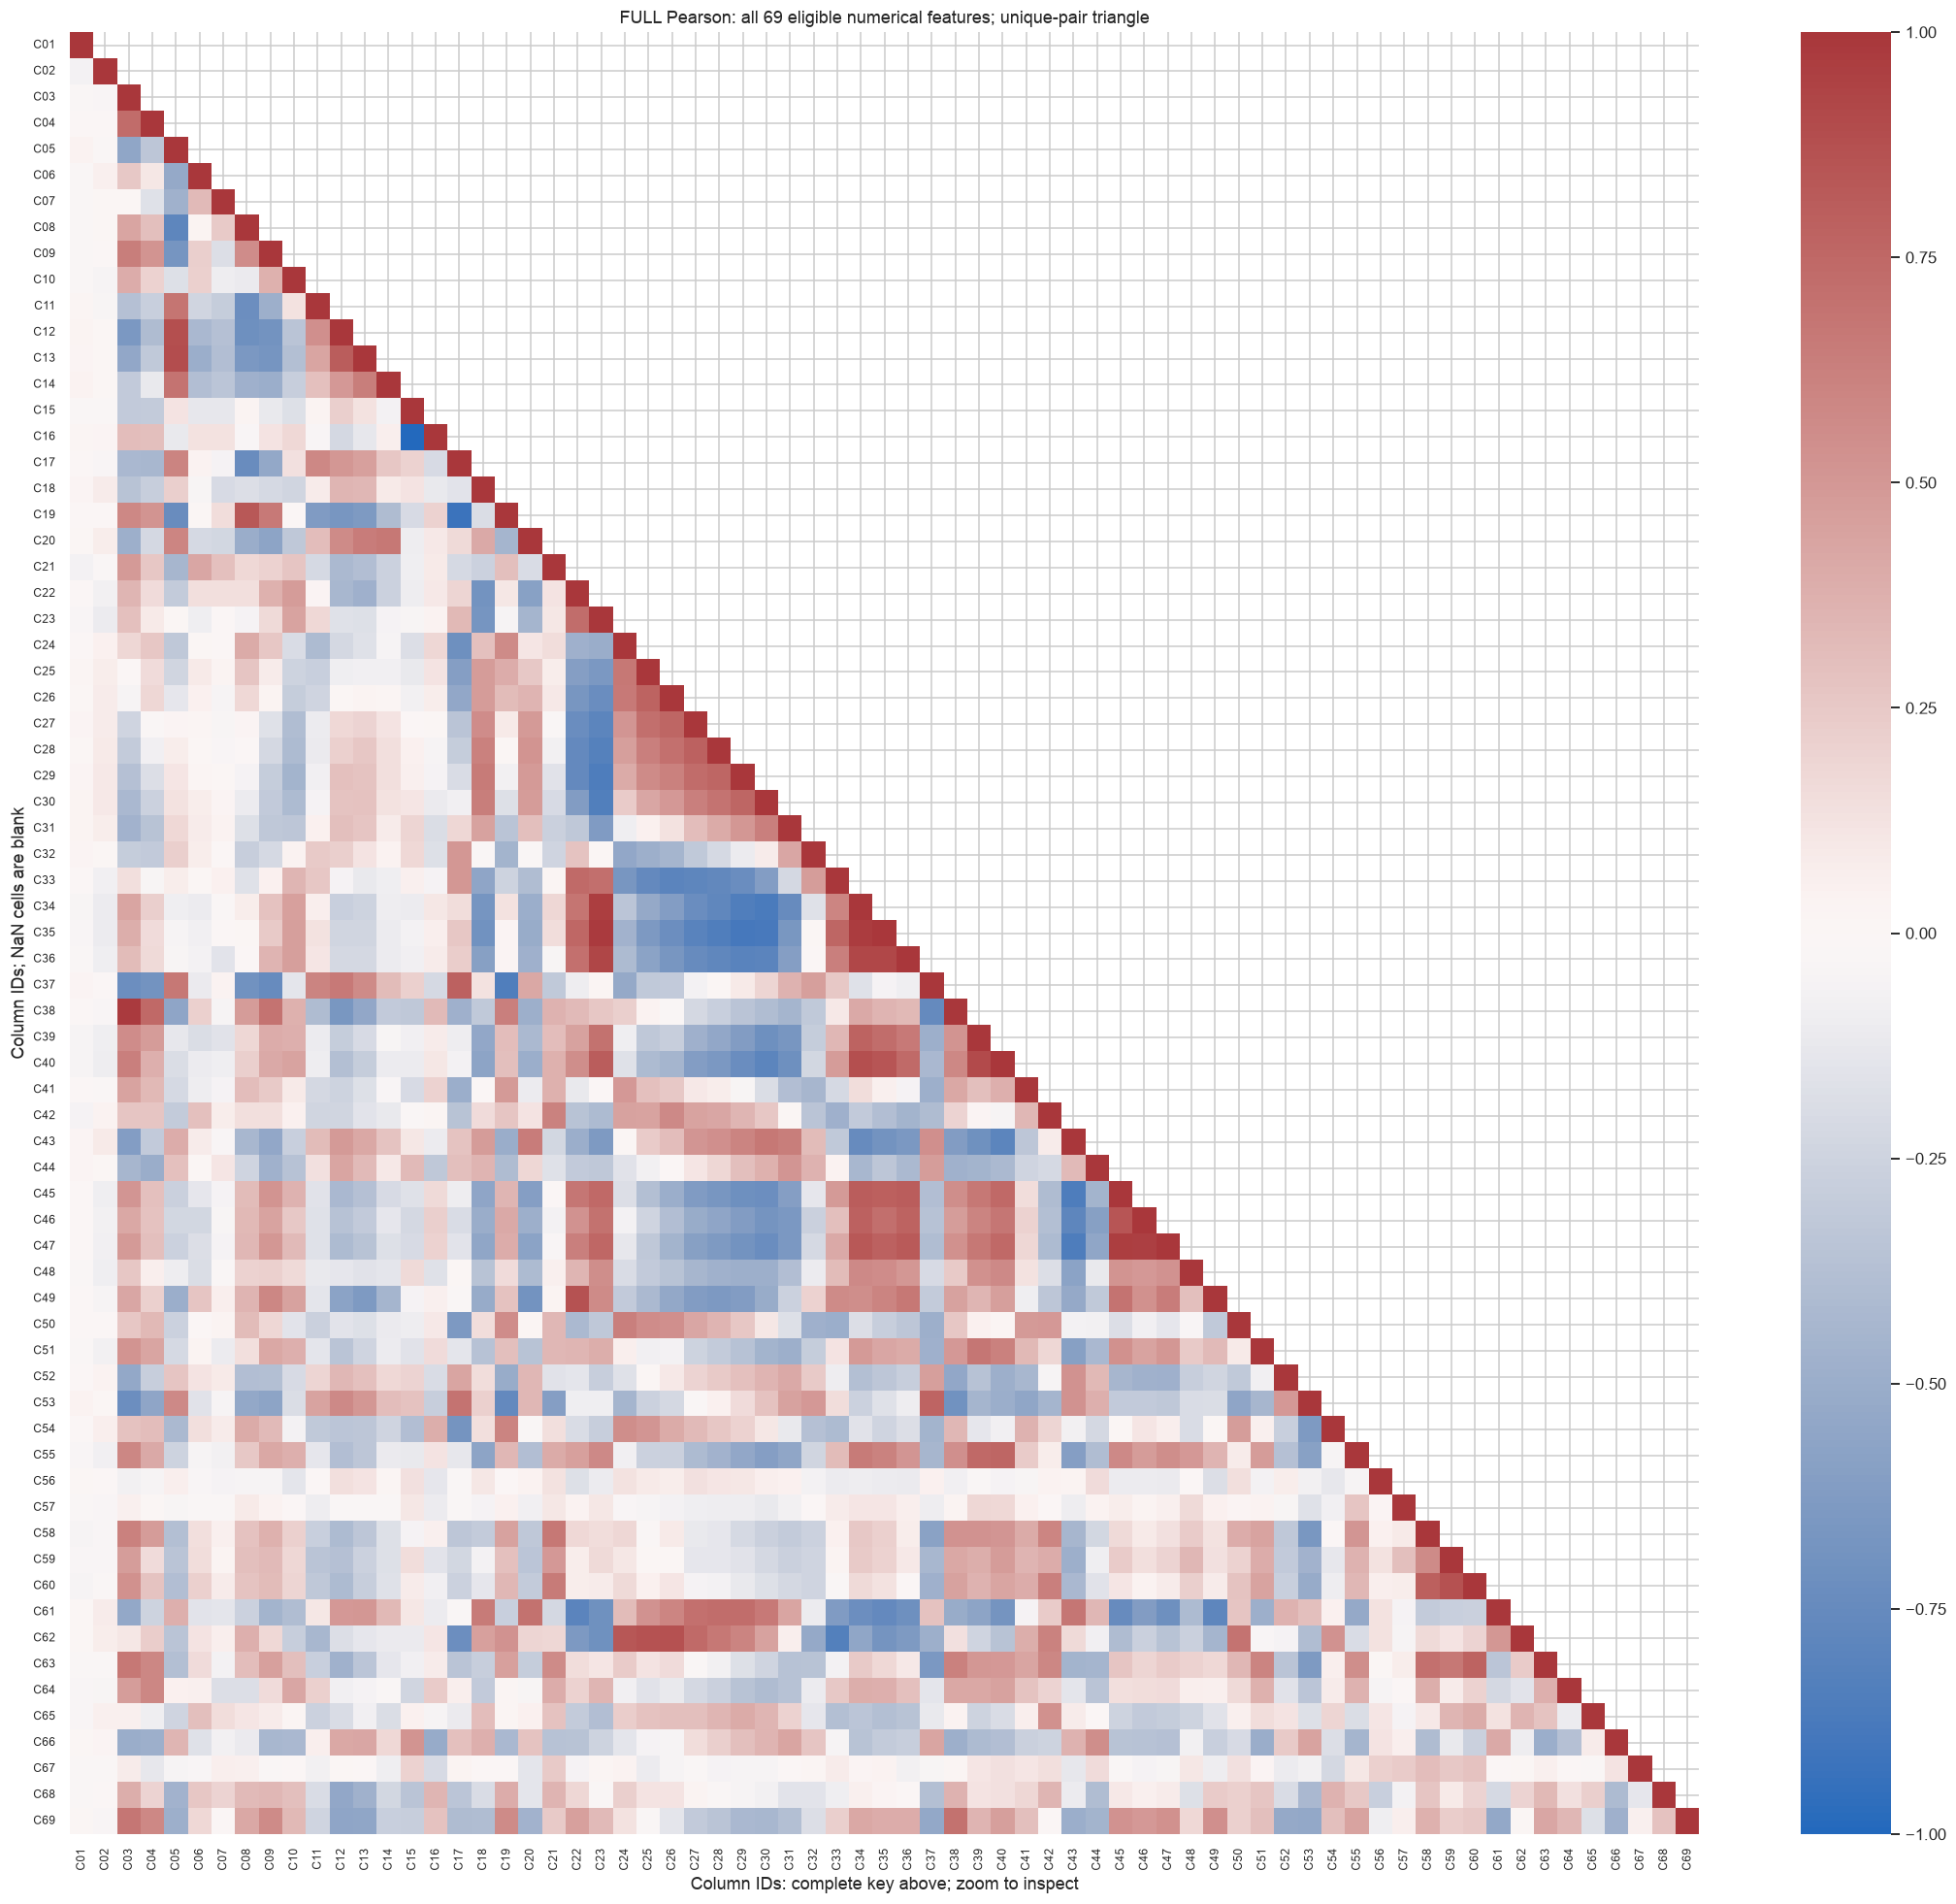

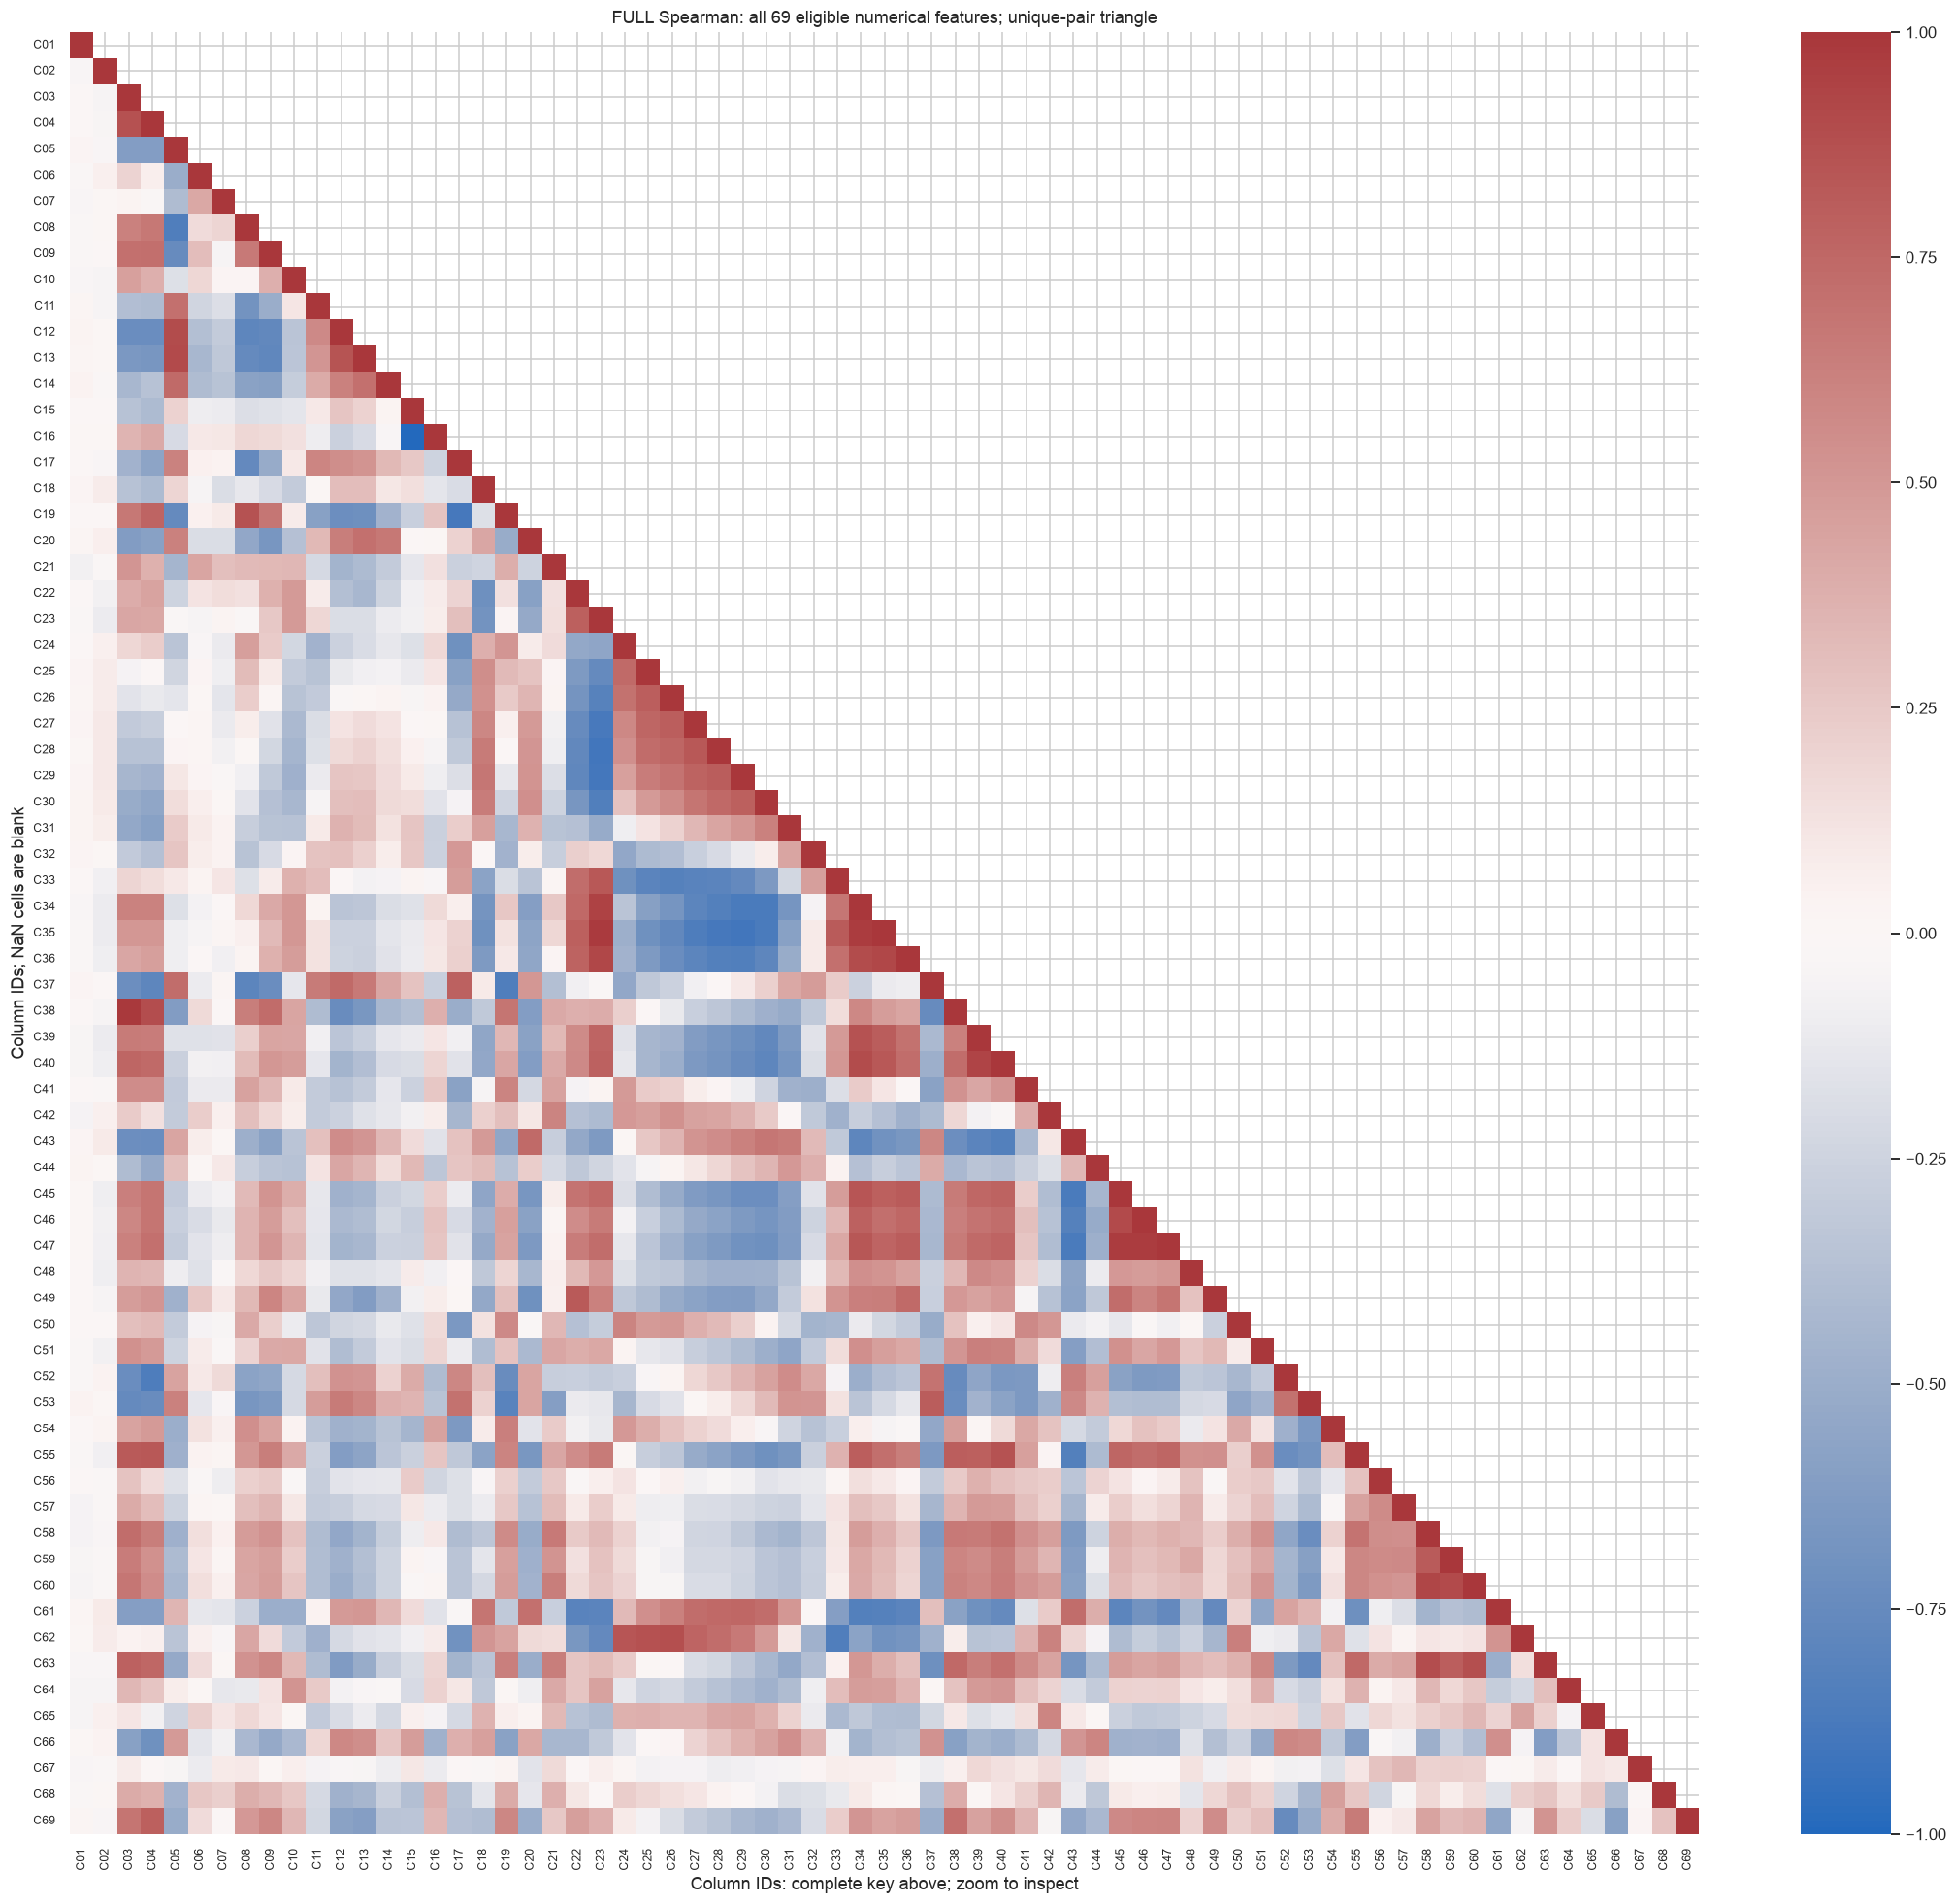

,feature_a,feature_b,pearson_r,spearman_r,paired_n,exceeds_pearson_threshold,exceeds_spearman_threshold,interpretation
169,population,housing_units,0.98285,0.98683,12905,True,True,Shared contextual/compositional information is a candidate explanation; verify formulas and...
273,age_median,age_70s,0.88704,0.90256,12905,False,True,Shared contextual/compositional information is a candidate explanation; verify formulas and...
861,male,female,-1.00000,-1.00000,12905,True,True,Shared contextual/compositional information is a candidate explanation; verify formulas and...
969,married,never_married,-0.92633,-0.88970,12905,True,False,Shared contextual/compositional information is a candidate explanation; verify formulas and...
1269,income_household_median,income_household_20_to_25,-0.82186,-0.90100,12902,False,True,Shared contextual/compositional information is a candidate explanation; verify formulas and...
1275,income_household_median,income_household_150_over,0.96608,0.93947,12902,True,True,Shared contextual/compositional information is a candidate explanation; verify formulas and...
1276,income_household_median,income_household_six_figure,0.97941,0.98175,12902,True,True,Shared contextual/compositional information is a candidate explanation; verify formulas and...
1277,income_household_median,income_individual_median,0.92813,0.91749,12902,True,True,Shared contextual/compositional information is a candidate explanation; verify formulas and...
1531,income_household_25_to_35,income_household_six_figure,-0.88668,-0.90290,12902,False,True,Shared contextual/compositional information is a candidate explanation; verify formulas and...
1716,income_household_150_over,income_household_six_figure,0.97341,0.97151,12902,True,True,Shared contextual/compositional information is a candidate explanation; verify formulas and...


All unique eligible pairs: 2346
Strong Pearson pairs: 12
Strong Spearman pairs: 15
Union of strong pairs: 17
Untestable/insufficiently observed pairs: 0


,unique_pairs,Pearson_above_threshold,Spearman_above_threshold
group,,,
Age summaries/shares,1,0,1
Demographic shares,4,2,3
Education shares,2,2,2
Housing/population,2,2,2
Income summaries/brackets,8,6,7


,relationship,paired_n,median_abs_residual,max_abs_residual,fraction_within_1e-6,interpretation
0,male + female versus 100,12905,0.000000e+00,6.666670e-03,0.962108,not exact; a compositional explanation still n...
1,bachelors + graduate versus college_or_above,12905,3.552714e-15,1.000001e-08,1.000000,numerically redundant at tolerance 1e-6
2,income_100_to_150 + income_150_over versus six...,12902,3.552714e-15,1.000000e-08,1.000000,numerically redundant at tolerance 1e-6


Relationships numerically exact at tolerance 1e-6: 2


**Observed:** 12,906 patient records share **739 ZIP categories**, with a median of **9 patients per ZIP**. Repeated contextual values change weighting and weaken independent-observation assumptions. Later inference or evaluation should consider geographic grouping and spatial dependence.

In [13]:
correlation_focus = ["patient_age", "bmi", "income_household_median", "poverty",
                     "education_college_or_above", "health_uninsured"]
assert set(correlation_focus).issubset(continuous_columns)
pearson = df[correlation_focus].corr(method="pearson", min_periods=MIN_CORRELATION_N)
spearman = df[correlation_focus].corr(method="spearman", min_periods=MIN_CORRELATION_N)
observed_mask = df[correlation_focus].notna().astype(int)
pairwise_n = observed_mask.T @ observed_mask
# The six-variable coefficients remain available; a duplicate small heatmap is unnecessary.
display(HTML(
    "<details><summary>Supplement: six-variable Pearson, Spearman and paired N</summary>"
    + pearson.round(4).to_html() + spearman.round(4).to_html() + pairwise_n.to_html() + "</details>"
))

correlation_diagnostics = audit.loc[continuous_columns, ["observed_unique", "dominant_observed_pct", "missing_pct"]].copy()
correlation_diagnostics["constant"] = correlation_diagnostics.observed_unique <= 1
correlation_diagnostics["near_constant"] = (
    (correlation_diagnostics.observed_unique > 1) &
    (correlation_diagnostics.dominant_observed_pct >= 100 * NEAR_CONSTANT_SHARE)
)
correlation_columns = [c for c in continuous_columns if not correlation_diagnostics.loc[c, "constant"]]
# Exclusion here is from a diagnostic matrix only; no raw frame columns are dropped.
all_pearson = df[correlation_columns].corr(method="pearson", min_periods=MIN_CORRELATION_N)
all_spearman = df[correlation_columns].corr(method="spearman", min_periods=MIN_CORRELATION_N)
all_observed = df[correlation_columns].notna().astype(int)
all_pairwise_n = all_observed.T @ all_observed
correlation_key = pd.DataFrame({"plot_id": [f"C{i+1:02}" for i in range(len(correlation_columns))],
                                "feature": correlation_columns})
display(HTML(
    "<details><summary>Full numerical audit and heatmap feature key (all features)</summary>"
    + correlation_diagnostics.to_html() + correlation_key.to_html(index=False) + "</details>"
))
display(HTML(
    "<details><summary>Complete numerical tables: Pearson, Spearman and paired N (69×69 each)</summary>"
    + "<h4>Pearson</h4>" + all_pearson.round(4).to_html()
    + "<h4>Spearman</h4>" + all_spearman.round(4).to_html()
    + "<h4>Paired N</h4>" + all_pairwise_n.to_html() + "</details>"
))
for matrix, name in [(all_pearson, "Pearson"), (all_spearman, "Spearman")]:
    fig, ax = plt.subplots(figsize=(20, 18))
    sns.heatmap(matrix, vmin=-1, vmax=1, center=0, cmap="vlag", annot=False,
                mask=np.triu(np.ones(matrix.shape, dtype=bool), k=1),
                xticklabels=correlation_key.plot_id, yticklabels=correlation_key.plot_id, ax=ax)
    ax.tick_params(axis="both", labelsize=8)
    ax.set(title=f"FULL {name}: all {len(correlation_columns)} eligible numerical features; unique-pair triangle",
           xlabel="Column IDs: complete key above; zoom to inspect", ylabel="Column IDs; NaN cells are blank")
    plt.tight_layout()
    plt.show()

correlation_pairs = []
for i, left in enumerate(correlation_columns):
    for right in correlation_columns[i+1:]:
        r, rho = all_pearson.loc[left, right], all_spearman.loc[left, right]
        exceeds_r = bool(pd.notna(r) and abs(r) > STRONG_CORRELATION)
        exceeds_rho = bool(pd.notna(rho) and abs(rho) > STRONG_CORRELATION)
        shared_context = (left not in individual_numeric and right not in individual_numeric)
        interpretation = ("Shared contextual/compositional information is a candidate explanation; verify formulas and ZIP grain"
                          if shared_context else "Individual/contextual association; verify measurement and selection")
        correlation_pairs.append({"feature_a": left, "feature_b": right, "pearson_r": r,
                                  "spearman_r": rho, "paired_n": int(all_pairwise_n.loc[left, right]),
                                  "exceeds_pearson_threshold": exceeds_r,
                                  "exceeds_spearman_threshold": exceeds_rho,
                                  "interpretation": interpretation,
                                  "abs_spearman": abs(rho) if pd.notna(rho) else np.nan})
all_unique_pairs = pd.DataFrame(correlation_pairs)
strong_correlations = all_unique_pairs.loc[
    all_unique_pairs.exceeds_pearson_threshold | all_unique_pairs.exceeds_spearman_threshold
].copy()
# Keep the original top-Spearman teaching summary as a supplement, not as the full audit.
strong_pairs = all_unique_pairs.sort_values("abs_spearman", ascending=False).rename(columns={"spearman_r": "spearman"})
assert len(all_unique_pairs) == len(correlation_columns) * (len(correlation_columns)-1) // 2
assert not all_unique_pairs.duplicated(["feature_a", "feature_b"]).any()
assert (all_unique_pairs.feature_a != all_unique_pairs.feature_b).all()
with pd.option_context("display.max_rows", None, "display.max_colwidth", 95):
    display(strong_correlations[["feature_a", "feature_b", "pearson_r", "spearman_r", "paired_n",
                                 "exceeds_pearson_threshold", "exceeds_spearman_threshold", "interpretation"]].round(5))
print("All unique eligible pairs:", len(all_unique_pairs))
print("Strong Pearson pairs:", int(all_unique_pairs.exceeds_pearson_threshold.sum()))
print("Strong Spearman pairs:", int(all_unique_pairs.exceeds_spearman_threshold.sum()))
print("Union of strong pairs:", len(strong_correlations))
print("Untestable/insufficiently observed pairs:", int((all_unique_pairs.pearson_r.isna() | all_unique_pairs.spearman_r.isna()).sum()))

# Organize already identified pairs for review; no new correlation or hypothesis test.
redundancy_domains = {
    "Income summaries/brackets": {c for c in continuous_columns if c.startswith("income_")},
    "Education shares": {c for c in continuous_columns if c.startswith("education_")},
    "Age summaries/shares": {c for c in continuous_columns if c.startswith("age_")},
    "Demographic shares": {"male", "female", "married", "never_married", "race_other", "race_multiple", "hispanic"},
    "Housing/population": {"population", "housing_units", "home_value", "rent_median"},
}
strong_groups = []
for pair in strong_correlations.itertuples():
    group = next((name for name, members in redundancy_domains.items()
                  if pair.feature_a in members and pair.feature_b in members), "Other / cross-domain")
    strong_groups.append(group)
strong_group_summary = strong_correlations.assign(group=strong_groups).groupby("group").agg(
    unique_pairs=("feature_a", "size"),
    Pearson_above_threshold=("exceeds_pearson_threshold", "sum"),
    Spearman_above_threshold=("exceeds_spearman_threshold", "sum"),
)
assert strong_group_summary.unique_pairs.sum() == len(strong_correlations)
display(strong_group_summary)

# Check plausible algebraic relationships numerically, without asserting a data dictionary.
identity_records = []
for label, parts, total in [
    ("male + female versus 100", ["male", "female"], 100.0),
    ("bachelors + graduate versus college_or_above", ["education_bachelors", "education_graduate"], "education_college_or_above"),
    ("income_100_to_150 + income_150_over versus six_figure", ["income_household_100_to_150", "income_household_150_over"], "income_household_six_figure"),
]:
    left = df[parts].sum(axis=1, min_count=len(parts))
    right = df[total] if isinstance(total, str) else pd.Series(total, index=df.index)
    valid = left.notna() & right.notna()
    residual = (left.loc[valid] - right.loc[valid]).abs()
    identity_records.append({"relationship": label, "paired_n": int(valid.sum()),
                             "median_abs_residual": residual.median(), "max_abs_residual": residual.max(),
                             "fraction_within_1e-6": (residual <= 1e-6).mean(),
                             "interpretation": "numerically redundant at tolerance 1e-6" if residual.max() <= 1e-6
                             else "not exact; a compositional explanation still needs source verification"})
algebraic_checks = pd.DataFrame(identity_records)
display(algebraic_checks)
print("Relationships numerically exact at tolerance 1e-6:", int(algebraic_checks.max_abs_residual.le(1e-6).sum()))

geo_focus = ["population", "density", "income_household_median", "poverty", "Ozone", "PM25", "N02"]
zip_variation = df.groupby("patient_zip3")[geo_focus].nunique()
geo_audit = pd.DataFrame({"ZIPs_with_multiple_observed_values": (zip_variation > 1).sum(),
                          "ZIPs_with_any_observed_value": (zip_variation > 0).sum()})
cluster_sizes = df.groupby("patient_zip3").size()
geo_comparison_records = []
if (zip_variation <= 1).all().all():
    # first() is justified here only by the preceding observed-value consistency check.
    geo_by_zip = df.groupby("patient_zip3")[geo_focus].first()
    for left, right in [("income_household_median", "poverty"), ("density", "PM25")]:
        geo_comparison_records.append({
            "pair": f"{left} / {right}",
            "patient_weighted_spearman": df[[left, right]].corr(method="spearman").iloc[0, 1],
            "equal_ZIP_spearman": geo_by_zip[[left, right]].corr(method="spearman").iloc[0, 1],
            "paired_ZIPs": int((geo_by_zip[left].notna() & geo_by_zip[right].notna()).sum()),
        })
else:
    print("Within-ZIP inconsistencies found: no arbitrary first-value aggregation is used.")
display(HTML(
    "<details><summary>Supplement: ZIP consistency, cluster sizes and weighting sensitivity</summary>"
    + geo_audit.to_html() + cluster_sizes.describe().rename("patients_per_ZIP").to_frame().round(3).to_html()
    + pd.DataFrame(geo_comparison_records).round(4).to_html(index=False) + "</details>"
))
display(Markdown(
    f"**Observed:** {len(df):,} patient records share **{len(cluster_sizes)} ZIP categories**, "
    f"with a median of **{cluster_sizes.median():.0f} patients per ZIP**. "
    "Repeated contextual values change weighting and weaken independent-observation assumptions. "
    "Later inference or evaluation should consider geographic grouping and spatial dependence."
))

### 7.2 Supplementary: seven exploratory reference tests

These tests are **optional supporting diagnostics**, not required tabular EDA or feature-selection
rules. Keep the previously declared family and outputs; it is not preregistered.

- **Mann–Whitney (age/BMI):** two-sided equality of distributions, not simply medians; observed
  cases per feature, asymptotic ties handling. Class 1 is passed first, so signed rank-biserial
  `2U1/(n1*n0)−1` is positive for larger class 1 values. `U1/(n1*n0)` estimates superiority with
  half-weighted ties, not a median shift or standardized mean difference.
- **Chi-square (race/payer):** correction=False; this notebook conservatively withholds p unless
  all observed/expected cells≥5. Cramér's V=`sqrt(chi2/(n*min(r−1,c−1)))` is unsigned/uncorrected;
  no sparse levels are merged. Count support does not verify independent patients.
- **Fisher (BMI/race/payer missingness):** two-sided odds-ratio-one null, conditioned on margins;
  the reported effect is the class 1−0 missing-rate gap in percentage points, not an odds ratio.
- **Holm:** all seven p-values form the declared family; a withheld p contributes 1 and its
  adjusted value is hidden. Dependence between tests can be allowed when input p-values are valid;
  Holm cannot repair clustered observations, post-EDA selection or the other exploratory choices.

All p-values are independence-conditional references. Effect sizes, missing-case selection,
confounding and timing limit interpretation; significance is not practical/predictive/causal
value or a mechanism label. BMI is post-metastatic, and payer is at the metastatic date:
the results are retrospective and do not approve either variable/indicator for an earlier baseline.
See SciPy's [Mann–Whitney](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.mannwhitneyu.html)
and [contingency-test](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.chi2_contingency.html) references.


In [14]:
numerical_test_columns = ["patient_age", "bmi"]
categorical_test_columns = ["patient_race", "payer_type"]
missingness_test_columns = ["bmi", "patient_race", "payer_type"]
test_records = []
numeric_test_records = []
for column in numerical_test_columns:
    class1 = df.loc[(df[TARGET] == 1) & df[column].notna(), column]
    class0 = df.loc[(df[TARGET] == 0) & df[column].notna(), column]
    result = stats.mannwhitneyu(class1, class0, alternative="two-sided", method="asymptotic")
    probability_superiority = result.statistic / (len(class1) * len(class0))
    delta = 2 * probability_superiority - 1
    numeric_test_records.append({"feature": column, "n_class0": len(class0), "n_class1": len(class1),
                                 "median_class0": class0.median(), "median_class1": class1.median(),
                                 "U_class1": result.statistic,
                                 "P1_greater_plus_half_ties": probability_superiority,
                                 "rank_biserial_class1_minus_class0": delta, "p_raw": result.pvalue})
    test_records.append({"test": f"MW: {column}", "p_raw": result.pvalue,
                         "effect": delta, "effect_type": "rank-biserial", "n": len(class0)+len(class1)})
numeric_tests = pd.DataFrame(numeric_test_records).set_index("feature")
display(numeric_tests.style.format({"median_class0": "{:.3f}", "median_class1": "{:.3f}",
                                   "U_class1": "{:.0f}", "P1_greater_plus_half_ties": "{:.4f}",
                                   "rank_biserial_class1_minus_class0": "{:.4f}", "p_raw": "{:.3e}"}))

,n_class0,n_class1,median_class0,median_class1,U_class1,P1_greater_plus_half_ties,rank_biserial_class1_minus_class0,p_raw
feature,,,,,,,,
patient_age,4846,8060,58.000,59.000,20917378,0.5355,0.0711,1.252e-11
bmi,1626,2315,28.275,28.150,1852842,0.4922,-0.0155,4.055e-01


**Categorical comparisons:** inspect the observed/expected count checks and complete-case sample sizes before interpreting any reference p-value.

In [15]:
categorical_test_records = []
for column in categorical_test_columns:
    available = df[column].notna()
    table = pd.crosstab(df.loc[available, column], df.loc[available, TARGET]).reindex(columns=[0, 1], fill_value=0)
    assert table.shape[0] >= 2 and (table.sum(axis=0) > 0).all()
    result = stats.chi2_contingency(table.to_numpy(), correction=False)
    expected = result.expected_freq
    count_rule_ok = bool((table.to_numpy() >= 5).all() and (expected >= 5).all())
    p_value = result.pvalue if count_rule_ok else np.nan
    cramer_v = np.sqrt(result.statistic / (table.to_numpy().sum() * min(table.shape[0]-1, table.shape[1]-1)))
    categorical_test_records.append({"feature": column, "observed_n": int(table.to_numpy().sum()),
                                     "levels": len(table), "n_class0": int(table[0].sum()), "n_class1": int(table[1].sum()),
                                     "min_observed": table.to_numpy().min(),
                                     "min_expected": expected.min(), "expected_cells_lt5": int((expected < 5).sum()),
                                     "cramers_V": cramer_v, "p_raw": p_value,
                                     "count_rule": "passed" if count_rule_ok else "p-value withheld"})
    test_records.append({"test": f"Chi-square: {column}", "p_raw": p_value,
                         "effect": cramer_v, "effect_type": "Cramer's V", "n": int(table.to_numpy().sum())})
categorical_tests = pd.DataFrame(categorical_test_records).set_index("feature")
display(categorical_tests.style.format({"min_expected": "{:.2f}", "cramers_V": "{:.4f}", "p_raw": "{:.3e}"}))

,observed_n,levels,n_class0,n_class1,min_observed,min_expected,expected_cells_lt5,cramers_V,p_raw,count_rule
feature,,,,,,,,,,
patient_race,6521,5,2326,4195,135,130.19,0,0.0382,4.916e-02,passed
payer_type,11103,3,4316,6787,895,972.59,0,0.0356,8.753e-04,passed


**Missingness comparisons:** the three 2 × 2 tables use all labeled rows and diagnose recording differences only.

In [16]:
missing_test_records = []
for column in missingness_test_columns:
    table = pd.crosstab(df[column].isna(), df[TARGET]).reindex(index=[False, True], columns=[0, 1], fill_value=0)
    assert int(table.to_numpy().sum()) == len(df)
    result = stats.fisher_exact(table.to_numpy(), alternative="two-sided")
    difference_pp = missing_by_class.loc[column, "difference_pp_class1_minus_class0"]
    missing_test_records.append({"feature": column, "n": int(table.to_numpy().sum()),
                                 "missing_n_class0": int(table.loc[True, 0]),
                                 "missing_n_class1": int(table.loc[True, 1]),
                                 "missing_pct_class0": missing_by_class.loc[column, "missing_pct_class0"],
                                 "missing_pct_class1": missing_by_class.loc[column, "missing_pct_class1"],
                                 "difference_pp": difference_pp, "p_raw": result.pvalue})
    test_records.append({"test": f"Fisher missingness: {column}", "p_raw": result.pvalue,
                         "effect": difference_pp, "effect_type": "missingness difference (pp)", "n": len(df)})
missing_tests = pd.DataFrame(missing_test_records).set_index("feature")
display(missing_tests.style.format({"missing_pct_class0": "{:.3f}", "missing_pct_class1": "{:.3f}",
                                   "difference_pp": "{:.3f}", "p_raw": "{:.3e}"}))

,n,missing_n_class0,missing_n_class1,missing_pct_class0,missing_pct_class1,difference_pp,p_raw
feature,,,,,,,
bmi,12906,3220,5745,66.447,71.278,4.831,9.207e-09
patient_race,12906,2520,3865,52.002,47.953,-4.049,8.437e-06
payer_type,12906,530,1273,10.937,15.794,4.857,6.033e-15


**Joint interpretation:** apply Holm adjustment across the declared seven-test family (not a preregistered analysis) and compare p-values with effect sizes and selection caveats.

In [17]:
family_tests = pd.DataFrame(test_records).set_index("test")
declared_family_size = len(numerical_test_columns) + len(categorical_test_columns) + len(missingness_test_columns)
assert len(family_tests) == declared_family_size
# A withheld p-value contributes 1 to retain the seven-test family size;
# its adjusted value is then hidden instead of being presented as a tested hypothesis.
testable = family_tests.p_raw.notna()
p_for_adjustment = family_tests.p_raw.where(testable, 1.0).to_numpy()
_, adjusted, _, _ = multipletests(p_for_adjustment, alpha=0.05, method="holm")
family_tests["p_holm"] = np.where(testable, adjusted, np.nan)
print(f"Holm family: {declared_family_size} declared tests; p-values remain independence-conditional references.")
display(family_tests.style.format({"p_raw": "{:.3e}", "p_holm": "{:.3e}", "effect": "{:.4f}"}))
display(Markdown(
    f"**Interpretation:** patient-age medians are **{numeric_tests.loc['patient_age', 'median_class0']:.1f}** "
    f"(class 0) and **{numeric_tests.loc['patient_age', 'median_class1']:.1f}** (class 1), with "
    f"rank-biserial effect **{numeric_tests.loc['patient_age', 'rank_biserial_class1_minus_class0']:.4f}** "
    f"and Holm reference p = **{family_tests.loc['MW: patient_age', 'p_holm']:.3e}**. "
    f"The corresponding pairwise superiority estimate, counting ties as half, is "
    f"**{numeric_tests.loc['patient_age', 'P1_greater_plus_half_ties']:.4f}**, close to the no-ordering reference 0.5. "
    f"BMI's observed-case effect is **{numeric_tests.loc['bmi', 'rank_biserial_class1_minus_class0']:.4f}** "
    f"with Holm reference p = **{family_tests.loc['MW: bmi', 'p_holm']:.3e}**. "
    "BMI is documented post-metastatic; its comparison is retrospective, not evidence for a baseline predictor. "
    "Inspect effect magnitudes and case selection alongside p-values. These comparisons neither "
    "validate feature timing nor resolve geographic dependence, confounding, or missingness mechanisms."
))

Holm family: 7 declared tests; p-values remain independence-conditional references.


,p_raw,effect,effect_type,n,p_holm
test,,,,,
MW: patient_age,1.252e-11,0.0711,rank-biserial,12906,7.515e-11
MW: bmi,4.055e-01,-0.0155,rank-biserial,3941,4.055e-01
Chi-square: patient_race,4.916e-02,0.0382,Cramer's V,6521,9.832e-02
Chi-square: payer_type,8.753e-04,0.0356,Cramer's V,11103,2.626e-03
Fisher missingness: bmi,9.207e-09,4.8314,missingness difference (pp),12906,4.603e-08
Fisher missingness: patient_race,8.437e-06,-4.0488,missingness difference (pp),12906,3.375e-05
Fisher missingness: payer_type,6.033e-15,4.8572,missingness difference (pp),12906,4.223e-14


**Interpretation:** patient-age medians are **58.0** (class 0) and **59.0** (class 1), with rank-biserial effect **0.0711** and Holm reference p = **7.515e-11**. The corresponding pairwise superiority estimate, counting ties as half, is **0.5355**, close to the no-ordering reference 0.5. BMI's observed-case effect is **-0.0155** with Holm reference p = **4.055e-01**. BMI is documented post-metastatic; its comparison is retrospective, not evidence for a baseline predictor. Inspect effect magnitudes and case selection alongside p-values. These comparisons neither validate feature timing nor resolve geographic dependence, confounding, or missingness mechanisms.

## 8. Findings and candidate preprocessing roadmap

Seven observations below summarize the main analysis, not every diagnostic. Evidence is computed
from the training file; **all actions are proposals for later experiments**, with no established
benefit. Apply learned rules only inside training folds after fixing temporal eligibility and
the validation question. The whole labeled file has already informed EDA.


In [18]:
findings = pd.DataFrame([
    {"EDA finding": "Substantial / highly unequal missingness",
     "Actual evidence": f"BMI={missing_table.loc['bmi', 'missing_pct']:.2f}%, race={missing_table.loc['patient_race', 'missing_pct']:.2f}%; novel treatment={missing_table.loc['metastatic_first_novel_treatment', 'missing_pct']:.2f}% missing",
     "Implication": "Observed-case summaries may not represent missing cases; no mechanism confirmed; very sparse treatment cannot support routine imputation",
     "Candidate preprocessing action": "For eligible inputs, compare mean/median/mode, kNN and MICE with controlled masking RMSE; assess indicators/unknown levels and sensitivity"},
    {"EDA finding": "Evidence against marginal normality under the reference tests",
     "Actual evidence": f"{normality_counts['reject H0']}/{len(normality_table)} reject; {normality_counts['fail to reject H0']} fail to reject; {normality_counts['NOT TESTABLE']} not testable",
     "Implication": "Rejection is not an effect size or an automatic scaler rule; iid calibration is limited",
     "Candidate preprocessing action": "Compare Min-Max, Standard, Robust and Quantile uniform/normal using the feature-specific roadmap and downstream validation"},
    {"EDA finding": "Strong associations and numerical redundancy",
     "Actual evidence": f"{len(strong_correlations)} unique strong pairs ({int(all_unique_pairs.exceeds_pearson_threshold.sum())} Pearson / {int(all_unique_pairs.exceeds_spearman_threshold.sum())} Spearman); {int(algebraic_checks.max_abs_residual.le(1e-6).sum())} sum identities within 1e−6",
     "Implication": "Shared/compositional information; pairwise r does not diagnose every multivariable dependency",
     "Candidate preprocessing action": "Verify semantics; check design rank/VIF; compare representatives, regularization or PCA; no threshold-only dropping"},
    {"EDA finding": "ZIP cardinality makes a relative rarity cutoff blunt",
     "Actual evidence": f"{len(cluster_sizes)} ZIP categories; <1% covers {zip_support.loc['share < 1%', 'patients_pct']:.2f}% of patients, versus {zip_support.loc['count < 5', 'patients_pct']:.2f}% for count<5",
     "Implication": "Blind pooling can erase distinctions; unseen-category behavior matters",
     "Candidate preprocessing action": "Compare fold-local support rules/encodings and unknown handling; target encoding must be cross-validated"},
    {"EDA finding": "Right tails and empirical extreme-value flags",
     "Actual evidence": f"Density skew={numerical_summary.loc['density', 'sample_skewness']:.2f}; BMI Tukey flags={int(outlier_review.loc['bmi', 'flagged_n'])}/{int(outlier_review.loc['bmi', 'observed_n'])}",
     "Implication": "Flags are not confirmed data errors or clinical cutoffs",
     "Candidate preprocessing action": "Compare required IQR/Z-score, IF, LOF and DBSCAN diagnostics; assess overlap/distribution impact before any justified treatment"},
    {"EDA finding": "Temporal eligibility precedes numerical preprocessing",
     "Actual evidence": "Official dictionary places BMI and both novel-treatment fields after metastatic diagnosis; diagnosis-code dates remain unresolved",
     "Implication": "A post-event value or its missingness indicator cannot be made available at an earlier baseline by imputation",
     "Candidate preprocessing action": "Define prediction time and feature availability; separate supplied-table benchmarking from prospective prediction"},
    {"EDA finding": "Patient records share geographic context",
     "Actual evidence": f"{len(df):,} records / {len(cluster_sizes)} ZIPs; {len(contextual_columns)} contextual numeric columns; within-ZIP value/mask conflicts={value_conflicts}/{mask_conflicts}",
     "Implication": "Weighting and dependence affect interpretation; different ZIPs need not be independent",
     "Candidate preprocessing action": "Freeze ZIP-aware splits/CV appropriate to deployment; disclose post-EDA assessment and possible spatial dependence"},
])
display(findings.style.hide(axis="index").set_properties(**{
    "text-align": "left", "vertical-align": "top", "white-space": "normal", "max-width": "23em"
}))


EDA finding,Actual evidence,Implication,Candidate preprocessing action
Substantial / highly unequal missingness,"BMI=69.46%, race=49.47%; novel treatment=99.81% missing",Observed-case summaries may not represent missing cases; no mechanism confirmed; very sparse treatment cannot support routine imputation,"For eligible inputs, compare mean/median/mode, kNN and MICE with controlled masking RMSE; assess indicators/unknown levels and sensitivity"
Evidence against marginal normality under the reference tests,69/69 reject; 0 fail to reject; 0 not testable,Rejection is not an effect size or an automatic scaler rule; iid calibration is limited,"Compare Min-Max, Standard, Robust and Quantile uniform/normal using the feature-specific roadmap and downstream validation"
Strong associations and numerical redundancy,17 unique strong pairs (12 Pearson / 15 Spearman); 2 sum identities within 1e−6,Shared/compositional information; pairwise r does not diagnose every multivariable dependency,"Verify semantics; check design rank/VIF; compare representatives, regularization or PCA; no threshold-only dropping"
ZIP cardinality makes a relative rarity cutoff blunt,"739 ZIP categories; <1% covers 92.14% of patients, versus 3.64% for count<5",Blind pooling can erase distinctions; unseen-category behavior matters,Compare fold-local support rules/encodings and unknown handling; target encoding must be cross-validated
Right tails and empirical extreme-value flags,Density skew=4.04; BMI Tukey flags=2/3941,Flags are not confirmed data errors or clinical cutoffs,"Compare required IQR/Z-score, IF, LOF and DBSCAN diagnostics; assess overlap/distribution impact before any justified treatment"
Temporal eligibility precedes numerical preprocessing,Official dictionary places BMI and both novel-treatment fields after metastatic diagnosis; diagnosis-code dates remain unresolved,A post-event value or its missingness indicator cannot be made available at an earlier baseline by imputation,Define prediction time and feature availability; separate supplied-table benchmarking from prospective prediction
Patient records share geographic context,"12,906 records / 739 ZIPs; 67 contextual numeric columns; within-ZIP value/mask conflicts=0/0",Weighting and dependence affect interpretation; different ZIPs need not be independent,Freeze ZIP-aware splits/CV appropriate to deployment; disclose post-EDA assessment and possible spatial dependence


### EDA conclusion

The next stage should address missingness, scale/tail sensitivity, overlapping contextual
features and categorical support, using the candidate comparisons above. Normality rejections,
correlation thresholds and Tukey flags do not select a method. First fix prediction time:
post-metastatic BMI/treatment and their indicators are not approved for an earlier baseline.
Little's age/BMI reference does not establish global MCAR, MAR or MNAR; transparent assumptions
and sensitivity experiments are needed. No preprocessing method/model has been fitted.

### Validation plan — proposed, not executed

All rows/labels informed this EDA. A split now is a **post-EDA internal assessment**, not a
completely untouched test. Independent external data would be needed for a fresh assessment.

1. Confirm deployment: new-ZIP generalization requires ZIP-disjoint partitions; future patients
   in known ZIPs answer a different question and warrant a ZIP-disjoint sensitivity assessment.
   Distinct IDs do not establish distinct people or independence; neighboring ZIPs may correlate.
2. Freeze a proposed new-ZIP development/assessment split using
   `GroupShuffleSplit(test_size=0.20, random_state=42)`. Here 20% means **groups, not patients**;
   verify counts/class support without searching seeds for better performance.
3. Compare within development data using proposed five-fold
   `StratifiedGroupKFold(shuffle=True, random_state=42)`. Check ID/ZIP non-overlap, fold sizes and
   both-class support (stratification is not guaranteed). Fit imputation, scaling, category maps,
   selection and resampling only in each training fold. Predeclare metrics/variability; wider
   tuning may need nested grouped CV. Evaluate the reserved part once after choices are fixed.

This plan limits further leakage; it cannot undo whole-file EDA exposure or guarantee spatial
independence. See [grouped-validation guidance](https://scikit-learn.org/stable/modules/cross_validation.html#cross-validation-iterators-for-grouped-data).

### Remaining gates and reproduction

- Resolve prediction/target date anchors, boundary/numeric coding, relevant ICD definitions,
  environmental units/years and the conflicting `poverty` entry; agree the benchmark/eligible inputs.
- Freeze validation and resolve instructor-specific rubric ambiguities in `RUBRIC_AUDIT.md`.
  Formal global MCAR inference remains BLOCKED; extra generic plots/tests will not establish it.

Restart the project's `.venv` kernel and run all cells from the root or `book/tabular/` with
local `data/raw/training.csv`. For another dataset, review the configuration and semantic/test
lists. The final cell verifies raw-file checksum and frame/index/dtype/shape preservation.
The book builds saved aggregate outputs **without `--execute`**, CSV or Kaggle credentials in CI;
retain outputs or rerun locally after clearing them. Expand supplementary tables for full values.
No patient rows/IDs are published. See [MyST execution](https://mystmd.org/guide/execute-notebooks).

Required calculations are present, but execution alone is not full rubric compliance. The
project still needs preprocessing/evaluation chapters and mandatory part(b), image or text.
The complete future checklist remains in the audit. No imputation, scaling, encoding, feature
selection, outlier removal, resampling or training is performed here; publication is separate.


In [19]:
raw_sha256_after = hashlib.sha256(DATA_PATH.read_bytes()).hexdigest()
frame_fingerprint_after = hashlib.sha256(
    pd.util.hash_pandas_object(df, index=True).to_numpy().tobytes()
).hexdigest()
assert raw_sha256_after == raw_sha256_before, "Raw CSV changed during this notebook execution"
assert frame_fingerprint_after == frame_fingerprint_before, "Loaded training frame was mutated"
assert df.dtypes.equals(dtypes_before) and df.shape == shape_before
assert isinstance(df.patient_zip3.dtype, pd.StringDtype)
assert df.patient_zip3.equals(zip_tokens)
assert len(audit) == len(feature_columns) and len(family_tests) == declared_family_size
print("PASS: raw CSV SHA-256 unchanged; loaded frame values, index, dtypes and shape unchanged.")
print(f"PASS: {len(audit)} features audited; ZIP strings preserved and excluded from continuous analyses; "
      f"{len(family_tests)} independence-conditional reference tests reported.")
print("Read-only EDA execution finished. No transformed dataset, patient-row export, preprocessing fit, or model was produced.")
assert len(normality_table) == len(continuous_columns)
assert all_pearson.shape == all_spearman.shape == all_pairwise_n.shape
assert len(all_unique_pairs) == len(correlation_columns)*(len(correlation_columns)-1)//2
print("Required EDA calculations executed; Little calibration status:", little_report["decision"])


PASS: raw CSV SHA-256 unchanged; loaded frame values, index, dtypes and shape unchanged.
PASS: 81 features audited; ZIP strings preserved and excluded from continuous analyses; 7 independence-conditional reference tests reported.
Read-only EDA execution finished. No transformed dataset, patient-row export, preprocessing fit, or model was produced.
Required EDA calculations executed; Little calibration status: BLOCKED: calibrated MCAR inference; Gaussian/independence assumptions unsupported
